
# PRCP-1015 – EARTHQUAKE DAMAGE PREDICTION

## End-to-End Data Science and Machine Learning Project

### 1. Project Overview

The objective of this project is to analyze building characteristics and develop a Machine Learning model to predict the level of damage caused to buildings during the 2015 Gorkha earthquake in Nepal.

The project uses information related to building location, age, physical structure, construction materials, foundation, roof type and other characteristics to predict the building damage category.

### 2. Problem Statement

The task is to predict the ordinal target variable `damage_grade`, which represents the level of damage experienced by a building during an earthquake.

The target variable contains three categories:

- Grade 1: Low damage
- Grade 2: Medium damage
- Grade 3: Almost complete destruction

### 3. Project Objectives

1. Perform Exploratory Data Analysis (EDA) to understand the dataset.
2. Identify patterns and relationships between building characteristics and damage grades.
3. Clean and preprocess the dataset for Machine Learning.
4. Develop multiple classification models to predict building damage.
5. Compare model performance using appropriate evaluation metrics.
6. Identify important building characteristics associated with damage.
7. Provide evidence-based suggestions to seismologists and disaster-management authorities.
8. Document challenges, solutions and project findings.

### 4. Dataset Files

Two CSV files are provided:

- `train_values.csv`: Contains building information and independent features.
- `train_labels.csv`: Contains building IDs and their actual damage grades.

The two files will be connected using `building_id`.

### 5. Machine Learning Objective

**Input:** Building characteristics.

**Output:** Predicted damage grade (1, 2 or 3).

This is a supervised classification problem with an ordinal target variable.

### 6. Project Workflow

1. Project Understanding
2. Data Loading and Inspection
3. Data Quality Assessment
4. Exploratory Data Analysis
5. Feature Engineering and Preprocessing
6. Train-Validation Splitting
7. Baseline Model Development
8. Machine Learning Model Development
9. Model Optimization
10. Model Evaluation and Comparison
11. Final Model Testing
12. Seismologist Recommendations
13. Challenges and Solutions
14. Final Conclusion

### 7. Tools and Technologies

- Python
- Jupyter Notebook
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn
- XGBoost / CatBoost (subject to experimentation)

### 8. Expected Outcome

Develop a reliable experimental classification model that can identify building damage categories using building-related characteristics and provide insights that may support future earthquake damage mitigation planning.


In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# File and directory handling
from pathlib import Path

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

# Visualization settings
sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


In [3]:
# Identify the project directory
current_directory = Path.cwd()

if (current_directory / "Data").exists():
    project_path = current_directory

elif (current_directory / "EquakeDamagePred" / "Data").exists():
    project_path = current_directory / "EquakeDamagePred"

else:
    raise FileNotFoundError("Project Data folder not found.")

# Dataset directory
data_path = project_path / "Data"

# CSV file paths
values_path = data_path / "train_values.csv"
labels_path = data_path / "train_labels.csv"

# Verify file availability
print("Project directory:", project_path)
print("Data directory:", data_path)

print("train_values.csv exists:", values_path.exists())
print("train_labels.csv exists:", labels_path.exists())

Project directory: C:\Users\kalip\Desktop\DS projects\EquakeDamagePred
Data directory: C:\Users\kalip\Desktop\DS projects\EquakeDamagePred\Data
train_values.csv exists: True
train_labels.csv exists: True


In [4]:
train_values = pd.read_csv(values_path)

train_labels = pd.read_csv(labels_path)

print("Both datasets loaded successfully.")

Both datasets loaded successfully.


In [5]:
print("Train Values Shape:", train_values.shape)
print("Train Labels Shape:", train_labels.shape)

Train Values Shape: (260601, 39)
Train Labels Shape: (260601, 2)


In [6]:
print("TRAIN VALUES - First Five Records")
display(train_values.head())

print("TRAIN LABELS - First Five Records")
display(train_labels.head())

TRAIN VALUES - First Five Records


,building_id,geo_level_1_id,geo_level_2_id,geo_level_3_id,count_floors_pre_eq,age,area_percentage,height_percentage,land_surface_condition,foundation_type,roof_type,ground_floor_type,other_floor_type,position,plan_configuration,has_superstructure_adobe_mud,has_superstructure_mud_mortar_stone,has_superstructure_stone_flag,has_superstructure_cement_mortar_stone,has_superstructure_mud_mortar_brick,has_superstructure_cement_mortar_brick,has_superstructure_timber,has_superstructure_bamboo,has_superstructure_rc_non_engineered,has_superstructure_rc_engineered,has_superstructure_other,legal_ownership_status,count_families,has_secondary_use,has_secondary_use_agriculture,has_secondary_use_hotel,has_secondary_use_rental,has_secondary_use_institution,has_secondary_use_school,has_secondary_use_industry,has_secondary_use_health_post,has_secondary_use_gov_office,has_secondary_use_use_police,has_secondary_use_other
0,802906,6,487,12198,2,30,6,5,t,r,n,f,q,t,d,1,1,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0
1,28830,8,900,2812,2,10,8,7,o,r,n,x,q,s,d,0,1,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0
2,94947,21,363,8973,2,10,5,5,t,r,n,f,x,t,d,0,1,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0
3,590882,22,418,10694,2,10,6,5,t,r,n,f,x,s,d,0,1,0,0,0,0,1,1,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0
4,201944,11,131,1488,3,30,8,9,t,r,n,f,x,s,d,1,0,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0


TRAIN LABELS - First Five Records


,building_id,damage_grade
0,802906,3
1,28830,2
2,94947,3
3,590882,2
4,201944,3


In [7]:
print("TRAIN VALUES - Last Five Records")

display(train_values.tail())

print("TRAIN LABELS - Last Five Records")

display(train_labels.tail())

TRAIN VALUES - Last Five Records


,building_id,geo_level_1_id,geo_level_2_id,geo_level_3_id,count_floors_pre_eq,age,area_percentage,height_percentage,land_surface_condition,foundation_type,roof_type,ground_floor_type,other_floor_type,position,plan_configuration,has_superstructure_adobe_mud,has_superstructure_mud_mortar_stone,has_superstructure_stone_flag,has_superstructure_cement_mortar_stone,has_superstructure_mud_mortar_brick,has_superstructure_cement_mortar_brick,has_superstructure_timber,has_superstructure_bamboo,has_superstructure_rc_non_engineered,has_superstructure_rc_engineered,has_superstructure_other,legal_ownership_status,count_families,has_secondary_use,has_secondary_use_agriculture,has_secondary_use_hotel,has_secondary_use_rental,has_secondary_use_institution,has_secondary_use_school,has_secondary_use_industry,has_secondary_use_health_post,has_secondary_use_gov_office,has_secondary_use_use_police,has_secondary_use_other
260596,688636,25,1335,1621,1,55,6,3,n,r,n,f,j,s,q,0,1,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0
260597,669485,17,715,2060,2,0,6,5,t,r,n,f,q,s,d,0,1,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0
260598,602512,17,51,8163,3,55,6,7,t,r,q,f,q,s,d,0,1,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0
260599,151409,26,39,1851,2,10,14,6,t,r,x,v,s,j,d,0,0,0,0,0,1,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0
260600,747594,21,9,9101,3,10,7,6,n,r,n,f,q,j,d,0,1,0,0,0,0,0,0,0,0,0,v,3,0,0,0,0,0,0,0,0,0,0,0


TRAIN LABELS - Last Five Records


,building_id,damage_grade
260596,688636,2
260597,669485,3
260598,602512,3
260599,151409,2
260600,747594,3


In [8]:
print("Train Values Columns:")
print(train_values.columns.tolist())

print("\nTrain Labels Columns:")
print(train_labels.columns.tolist())

Train Values Columns:
['building_id', 'geo_level_1_id', 'geo_level_2_id', 'geo_level_3_id', 'count_floors_pre_eq', 'age', 'area_percentage', 'height_percentage', 'land_surface_condition', 'foundation_type', 'roof_type', 'ground_floor_type', 'other_floor_type', 'position', 'plan_configuration', 'has_superstructure_adobe_mud', 'has_superstructure_mud_mortar_stone', 'has_superstructure_stone_flag', 'has_superstructure_cement_mortar_stone', 'has_superstructure_mud_mortar_brick', 'has_superstructure_cement_mortar_brick', 'has_superstructure_timber', 'has_superstructure_bamboo', 'has_superstructure_rc_non_engineered', 'has_superstructure_rc_engineered', 'has_superstructure_other', 'legal_ownership_status', 'count_families', 'has_secondary_use', 'has_secondary_use_agriculture', 'has_secondary_use_hotel', 'has_secondary_use_rental', 'has_secondary_use_institution', 'has_secondary_use_school', 'has_secondary_use_industry', 'has_secondary_use_health_post', 'has_secondary_use_gov_office', 'has_se

In [9]:
print("TRAIN VALUES INFORMATION")
train_values.info()

print("\nTRAIN LABELS INFORMATION")
train_labels.info()

TRAIN VALUES INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 260601 entries, 0 to 260600
Data columns (total 39 columns):
 #   Column                                  Non-Null Count   Dtype 
---  ------                                  --------------   ----- 
 0   building_id                             260601 non-null  int64 
 1   geo_level_1_id                          260601 non-null  int64 
 2   geo_level_2_id                          260601 non-null  int64 
 3   geo_level_3_id                          260601 non-null  int64 
 4   count_floors_pre_eq                     260601 non-null  int64 
 5   age                                     260601 non-null  int64 
 6   area_percentage                         260601 non-null  int64 
 7   height_percentage                       260601 non-null  int64 
 8   land_surface_condition                  260601 non-null  object
 9   foundation_type                         260601 non-null  object
 10  roof_type                      


## Phase 2 – Data Loading and Initial Inspection

### Observations

1. Two CSV files, `train_values.csv` and `train_labels.csv`, were successfully loaded into Pandas DataFrames.

2. The input dataset contains 260,601 records and 39 columns.

3. The target dataset contains 260,601 records and 2 columns.

4. The input dataset contains building identification information and building-related features.

5. The target dataset contains the building ID and corresponding damage grade.

6. The `building_id` column will be used to connect the input features with their corresponding target labels.

7. Data types and column structures were inspected to understand the dataset before beginning detailed data-quality analysis and EDA.

### Conclusion

The initial inspection confirms that the dataset contains a large number of building records and the corresponding damage labels. The next step is to assess data quality, validate building IDs and investigate the target variable distribution.


In [10]:
 # Missing values in input dataset
print("TRAIN VALUES - Missing Value Count")
print(train_values.isnull().sum().sum())

# Missing values in target dataset
print("\nTRAIN LABELS - Missing Value Count")
print(train_labels.isnull().sum().sum())

TRAIN VALUES - Missing Value Count
0

TRAIN LABELS - Missing Value Count
0


In [11]:
# Calculate missing value statistics for input data
missing_values = pd.DataFrame({
    "Missing Count": train_values.isnull().sum(),
    "Missing Percentage": train_values.isnull().mean() * 100
})

missing_values = missing_values.sort_values(
    by="Missing Percentage",
    ascending=False
)

display(missing_values)

,Missing Count,Missing Percentage
building_id,0,0.0
has_secondary_use_agriculture,0,0.0
has_superstructure_bamboo,0,0.0
has_superstructure_rc_non_engineered,0,0.0
has_superstructure_rc_engineered,0,0.0
has_superstructure_other,0,0.0
legal_ownership_status,0,0.0
count_families,0,0.0
has_secondary_use,0,0.0
has_secondary_use_hotel,0,0.0


In [12]:
# Duplicate records in input dataset
values_duplicates = train_values.duplicated().sum()

# Duplicate records in target dataset
labels_duplicates = train_labels.duplicated().sum()

print("Duplicate rows in train_values:", values_duplicates)
print("Duplicate rows in train_labels:", labels_duplicates)

Duplicate rows in train_values: 0
Duplicate rows in train_labels: 0


In [13]:
print(
    "Duplicate Building IDs in train_values:",
    train_values["building_id"].duplicated().sum()
)

print(
    "Duplicate Building IDs in train_labels:",
    train_labels["building_id"].duplicated().sum()
)

Duplicate Building IDs in train_values: 0
Duplicate Building IDs in train_labels: 0


In [14]:
# Number of unique building IDs
values_unique_ids = train_values["building_id"].nunique()
labels_unique_ids = train_labels["building_id"].nunique()

print("Unique IDs in train_values:", values_unique_ids)
print("Unique IDs in train_labels:", labels_unique_ids)

# Check whether both datasets contain the same building IDs
same_ids = set(train_values["building_id"]) == set(train_labels["building_id"])

print("Do both datasets have matching IDs?", same_ids)

Unique IDs in train_values: 260601
Unique IDs in train_labels: 260601
Do both datasets have matching IDs? True


In [15]:
same_order = train_values["building_id"].equals(
    train_labels["building_id"]
)

print("Are building IDs in the same order?", same_order)

Are building IDs in the same order? True


In [16]:
# Identify binary-style columns
binary_columns = [
    col for col in train_values.columns
    if col.startswith("has_")
]

# Display unique values in each binary column
for col in binary_columns:
    print(col, ":", sorted(train_values[col].unique()))

has_superstructure_adobe_mud : [np.int64(0), np.int64(1)]
has_superstructure_mud_mortar_stone : [np.int64(0), np.int64(1)]
has_superstructure_stone_flag : [np.int64(0), np.int64(1)]
has_superstructure_cement_mortar_stone : [np.int64(0), np.int64(1)]
has_superstructure_mud_mortar_brick : [np.int64(0), np.int64(1)]
has_superstructure_cement_mortar_brick : [np.int64(0), np.int64(1)]
has_superstructure_timber : [np.int64(0), np.int64(1)]
has_superstructure_bamboo : [np.int64(0), np.int64(1)]
has_superstructure_rc_non_engineered : [np.int64(0), np.int64(1)]
has_superstructure_rc_engineered : [np.int64(0), np.int64(1)]
has_superstructure_other : [np.int64(0), np.int64(1)]
has_secondary_use : [np.int64(0), np.int64(1)]
has_secondary_use_agriculture : [np.int64(0), np.int64(1)]
has_secondary_use_hotel : [np.int64(0), np.int64(1)]
has_secondary_use_rental : [np.int64(0), np.int64(1)]
has_secondary_use_institution : [np.int64(0), np.int64(1)]
has_secondary_use_school : [np.int64(0), np.int64(1)]

In [17]:
# Identify categorical columns
categorical_columns = train_values.select_dtypes(
    include="object"
).columns

print("Number of categorical columns:", len(categorical_columns))

# Inspect unique categories
for col in categorical_columns:
    print("\n", col)
    print(train_values[col].value_counts())

Number of categorical columns: 8

 land_surface_condition
land_surface_condition
t    216757
n     35528
o      8316
Name: count, dtype: int64

 foundation_type
foundation_type
r    219196
w     15118
u     14260
i     10579
h      1448
Name: count, dtype: int64

 roof_type
roof_type
n    182842
q     61576
x     16183
Name: count, dtype: int64

 ground_floor_type
ground_floor_type
f    209619
x     24877
v     24593
z      1004
m       508
Name: count, dtype: int64

 other_floor_type
other_floor_type
q    165282
x     43448
j     39843
s     12028
Name: count, dtype: int64

 position
position
s    202090
t     42896
j     13282
o      2333
Name: count, dtype: int64

 plan_configuration
plan_configuration
d    250072
q      5692
u      3649
s       346
c       325
a       252
o       159
m        46
n        38
f        22
Name: count, dtype: int64

 legal_ownership_status
legal_ownership_status
v    250939
a      5512
w      2677
r      1473
Name: count, dtype: int64



## Phase 3 – Data Quality Assessment

### 1. Missing Value Analysis

Missing values were checked in both input and target datasets.

The analysis found no missing values in either dataset. Therefore, no missing-value imputation was required during the initial data-quality assessment.

### 2. Duplicate Record Analysis

Duplicate records were checked in both datasets.

No duplicate rows were identified in the input or target datasets. Duplicate building identifiers were also checked to ensure that each building was represented uniquely.

### 3. Building ID Validation

The `building_id` column was examined to verify the relationship between the input and target datasets.

Both datasets contain the same number of unique building IDs, and the identifiers match between the two files.

The building IDs were therefore suitable for merging the datasets.

### 4. Binary Feature Validation

The binary-style `has_` columns were examined to verify their unique values.

This check helps identify unexpected values in the construction-material and secondary-usage indicators.

### 5. Categorical Feature Inspection

The eight categorical features were identified and their available categories were examined.

These features represent building characteristics such as foundation, roof type, ground-floor construction, land surface condition and ownership status.

### Conclusion

The initial data-quality checks did not identify missing values or duplicate records. The building identifiers were also found to match between the input and target datasets.

The dataset is therefore suitable for proceeding to further exploratory analysis, subject to additional checks on unusual values and feature distributions.


In [18]:
# Merge building features with their actual damage grades

earthquake_df = pd.merge(
    train_values,
    train_labels,
    on="building_id",
    how="inner",
    validate="one_to_one"
)

print("Combined dataset created successfully.")

print("Combined dataset shape:", earthquake_df.shape)

display(earthquake_df.head())

Combined dataset created successfully.
Combined dataset shape: (260601, 40)


,building_id,geo_level_1_id,geo_level_2_id,geo_level_3_id,count_floors_pre_eq,age,area_percentage,height_percentage,land_surface_condition,foundation_type,roof_type,ground_floor_type,other_floor_type,position,plan_configuration,has_superstructure_adobe_mud,has_superstructure_mud_mortar_stone,has_superstructure_stone_flag,has_superstructure_cement_mortar_stone,has_superstructure_mud_mortar_brick,has_superstructure_cement_mortar_brick,has_superstructure_timber,has_superstructure_bamboo,has_superstructure_rc_non_engineered,has_superstructure_rc_engineered,has_superstructure_other,legal_ownership_status,count_families,has_secondary_use,has_secondary_use_agriculture,has_secondary_use_hotel,has_secondary_use_rental,has_secondary_use_institution,has_secondary_use_school,has_secondary_use_industry,has_secondary_use_health_post,has_secondary_use_gov_office,has_secondary_use_use_police,has_secondary_use_other,damage_grade
0,802906,6,487,12198,2,30,6,5,t,r,n,f,q,t,d,1,1,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,3
1,28830,8,900,2812,2,10,8,7,o,r,n,x,q,s,d,0,1,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,2
2,94947,21,363,8973,2,10,5,5,t,r,n,f,x,t,d,0,1,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,3
3,590882,22,418,10694,2,10,6,5,t,r,n,f,x,s,d,0,1,0,0,0,0,1,1,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,2
4,201944,11,131,1488,3,30,8,9,t,r,n,f,x,s,d,1,0,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,3


In [20]:
# Count the number of buildings in each damage category

damage_counts = earthquake_df["damage_grade"].value_counts().sort_index()

print("Damage Grade Distribution:")
display(damage_counts)

Damage Grade Distribution:


damage_grade
1     25124
2    148259
3     87218
Name: count, dtype: int64

In [21]:
# Calculate percentage distribution of damage grades

damage_percentages = (
    earthquake_df["damage_grade"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

damage_distribution = pd.DataFrame({
    "Building Count": damage_counts,
    "Percentage": damage_percentages
})

display(damage_distribution.round(2))

,Building Count,Percentage
damage_grade,,
1,25124,9.64
2,148259,56.89
3,87218,33.47


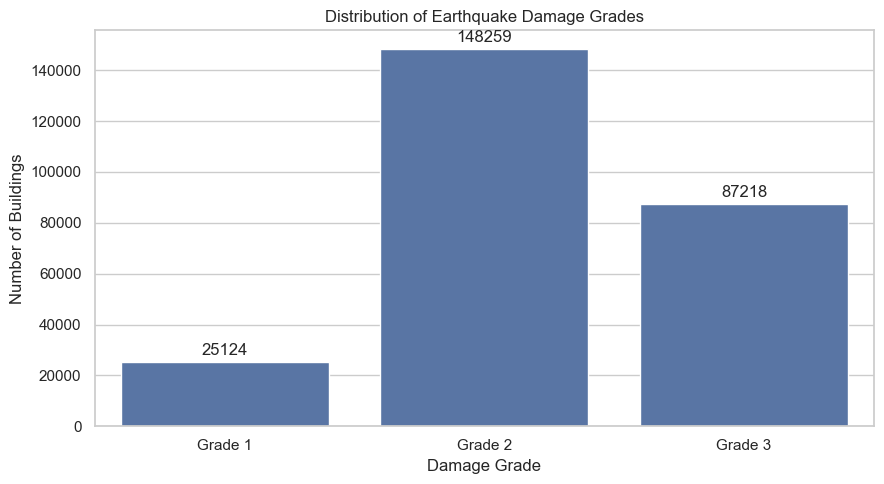

In [22]:
plt.figure(figsize=(9, 5))

ax = sns.countplot(
    data=earthquake_df,
    x="damage_grade",
    order=[1, 2, 3]
)

plt.title("Distribution of Earthquake Damage Grades")
plt.xlabel("Damage Grade")
plt.ylabel("Number of Buildings")
plt.xticks([0, 1, 2], ["Grade 1", "Grade 2", "Grade 3"])

# Display count above each bar
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

plt.tight_layout()
plt.show()

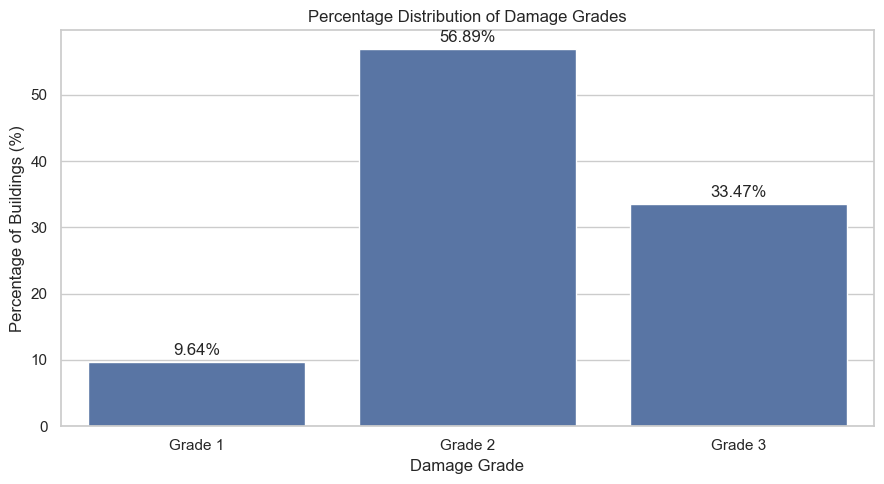

In [23]:
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    x=damage_distribution.index,
    y=damage_distribution["Percentage"]
)

plt.title("Percentage Distribution of Damage Grades")
plt.xlabel("Damage Grade")
plt.ylabel("Percentage of Buildings (%)")
plt.xticks([0, 1, 2], ["Grade 1", "Grade 2", "Grade 3"])

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.tight_layout()
plt.show()


## Phase 4 – Exploratory Data Analysis

### 4.1 Target Variable Analysis

The target variable `damage_grade` represents the severity of building damage caused by the earthquake.

The target contains three categories:

- Grade 1: Low damage
- Grade 2: Medium damage
- Grade 3: Almost complete destruction

### 4.2 Data Integration

The input and target datasets were combined using the `building_id` column.

The resulting dataset contains building characteristics along with their corresponding damage grades.

### 4.3 Target Distribution Observations

The target distribution analysis showed that:

1. Grade 1 represents 9.64% of the observations.
2. Grade 2 represents 56.89% of the observations.
3. Grade 3 represents 33.47% of the observations.
4. Grade 2 is the most frequently occurring damage category.
5. Grade 1 is the least represented category.

### 4.4 Class Imbalance Observation

The target variable has an imbalanced class distribution. Grade 2 accounts for a significantly larger proportion of observations than Grade 1.

This imbalance needs to be considered during model development and evaluation.

Accuracy alone may not provide a complete picture of classification performance. Macro F1-score, class-wise recall and confusion matrices will also be considered.

### Conclusion

The target variable analysis provides an initial understanding of the distribution of building damage categories.

The next step is to examine numerical building characteristics to identify their distributions, unusual values and potential relationships with damage grades.


In [24]:
# Select numerical building characteristics

numeric_features = [
    "count_floors_pre_eq",
    "age",
    "area_percentage",
    "height_percentage",
    "count_families"
]

print("Numerical Features:")
print(numeric_features)

print("\nTotal Numerical Features:", len(numeric_features))

Numerical Features:
['count_floors_pre_eq', 'age', 'area_percentage', 'height_percentage', 'count_families']

Total Numerical Features: 5


In [25]:
# Generate descriptive statistics for numerical features

numeric_summary = earthquake_df[numeric_features].describe().T

display(numeric_summary)

,count,mean,std,min,25%,50%,75%,max
count_floors_pre_eq,260601.0,2.129723,0.727665,1.0,2.0,2.0,2.0,9.0
age,260601.0,26.535029,73.565937,0.0,10.0,15.0,30.0,995.0
area_percentage,260601.0,8.018051,4.392231,1.0,5.0,7.0,9.0,100.0
height_percentage,260601.0,5.434365,1.918418,2.0,4.0,5.0,6.0,32.0
count_families,260601.0,0.983949,0.418389,0.0,1.0,1.0,1.0,9.0


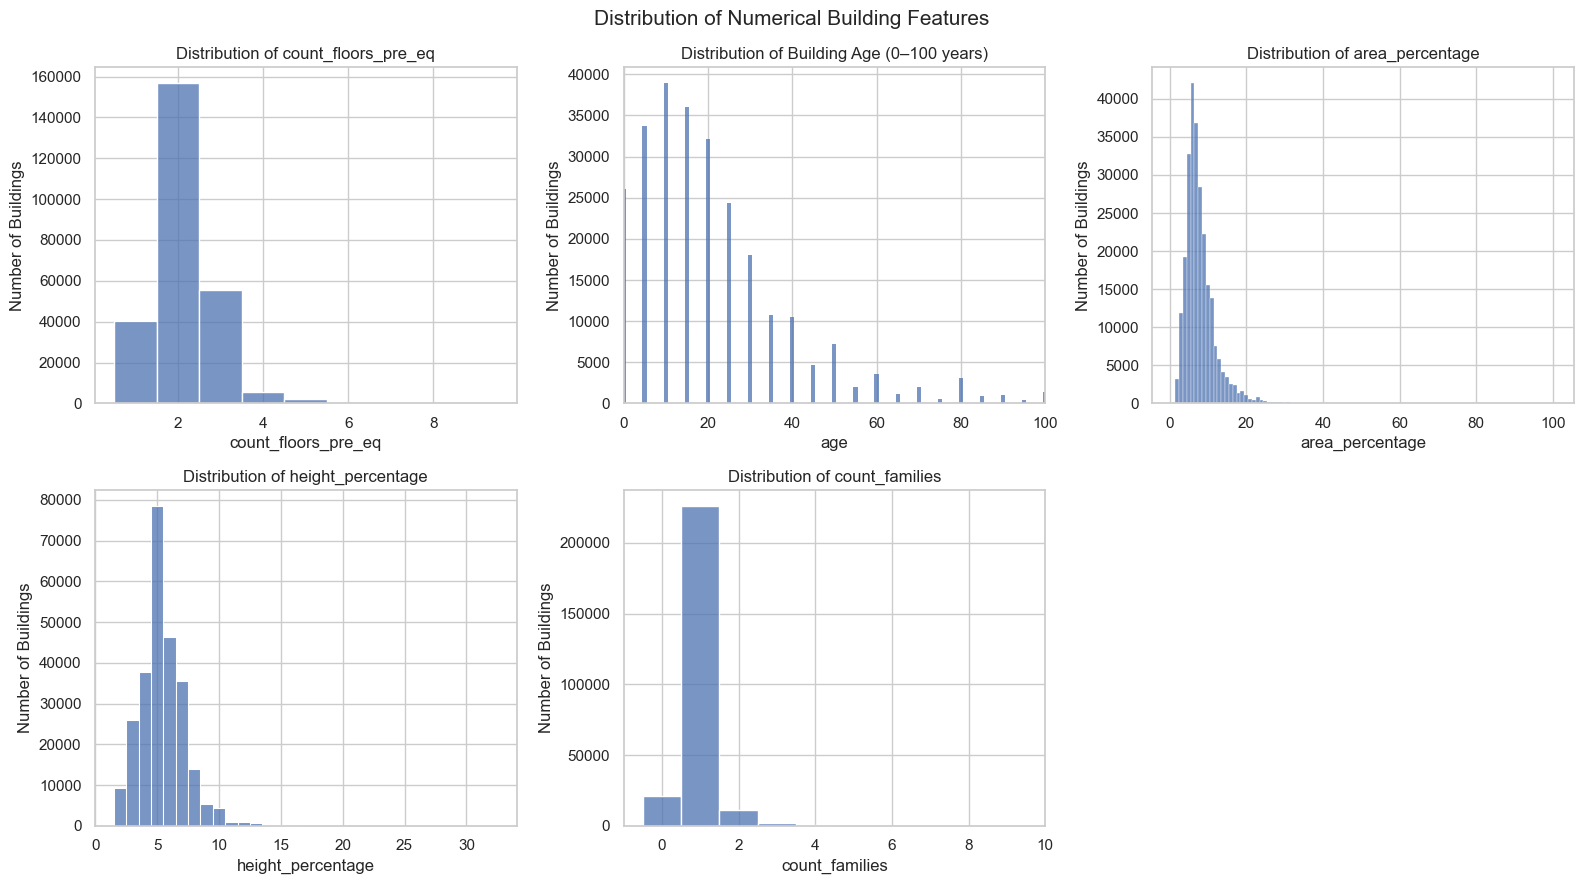

In [26]:
# Plot distributions of numerical features

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

axes = axes.flatten()

for i, feature in enumerate(numeric_features):

    sns.histplot(
        data=earthquake_df,
        x=feature,
        discrete=True,
        ax=axes[i]
    )

    axes[i].set_title(f"Distribution of {feature}")
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel("Number of Buildings")

    # Limit the displayed age range for better visibility
    if feature == "age":
        axes[i].set_xlim(0, 100)
        axes[i].set_title("Distribution of Building Age (0–100 years)")

# Hide the unused sixth subplot
axes[5].set_visible(False)

plt.suptitle(
    "Distribution of Numerical Building Features",
    fontsize=15
)

plt.tight_layout()
plt.show()

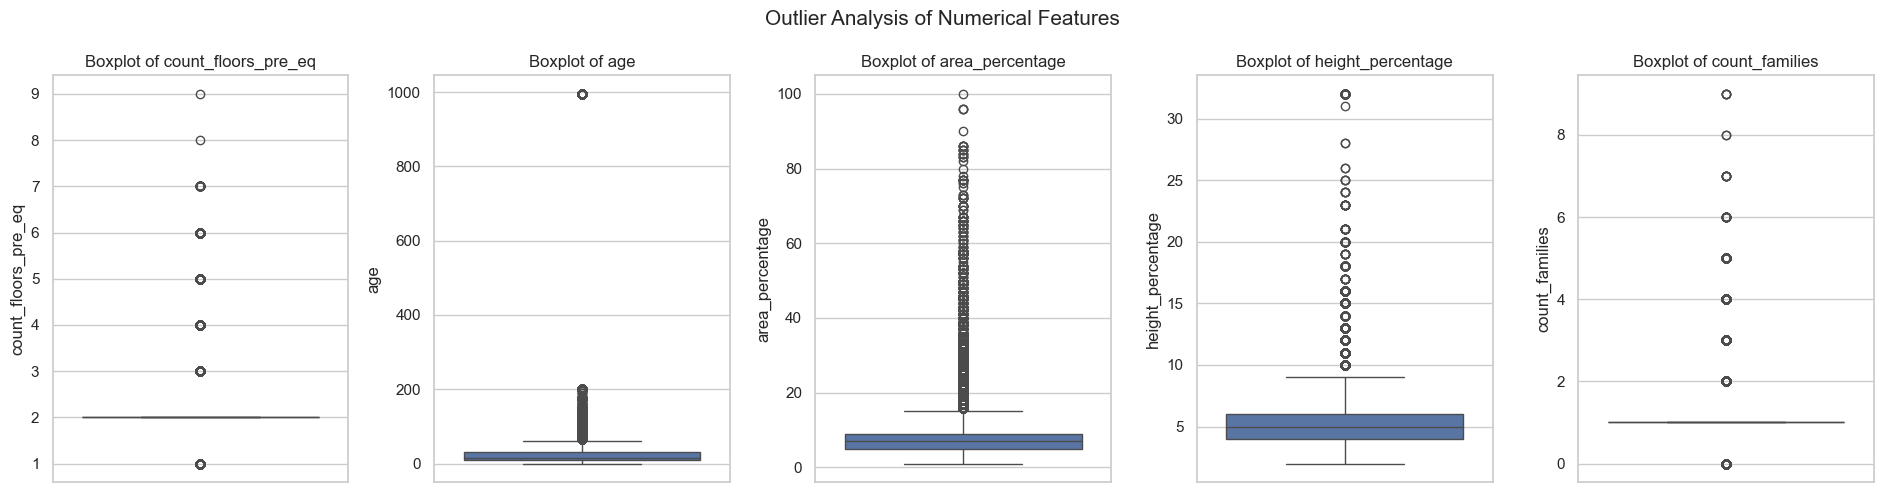

In [27]:
# Visualize potential outliers using boxplots

fig, axes = plt.subplots(1, 5, figsize=(19, 5))

for i, feature in enumerate(numeric_features):

    sns.boxplot(
        data=earthquake_df,
        y=feature,
        ax=axes[i]
    )

    axes[i].set_title(f"Boxplot of {feature}")
    axes[i].set_ylabel(feature)

plt.suptitle(
    "Outlier Analysis of Numerical Features",
    fontsize=15
)

plt.tight_layout()
plt.show()

In [29]:
# Statistical summary of building age

print("Building Age Summary:")
display(
    earthquake_df["age"].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

# Count buildings with age greater than 100 years

age_above_100 = (earthquake_df["age"] > 100).sum()

print("\nBuildings with age above 100:", age_above_100)

# Count buildings with age equal to zero

age_zero = (earthquake_df["age"] == 0).sum()

print("Buildings with age zero:", age_zero)

# Inspect unusually high age values

print("\nAge values above 100:")

display(
    earthquake_df.loc[
        earthquake_df["age"] > 100,
        "age"
    ].value_counts().sort_index()
)

Building Age Summary:


count    260601.000000
mean         26.535029
std          73.565937
min           0.000000
25%          10.000000
50%          15.000000
75%          30.000000
90%          45.000000
95%          60.000000
99%         100.000000
max         995.000000
Name: age, dtype: float64


Buildings with age above 100: 2124
Buildings with age zero: 26041

Age values above 100:


age
105      89
110     100
115      21
120     180
125      37
130       9
135       5
140       9
145       3
150     142
155       1
160       6
165       2
170       6
175       5
180       7
185       1
190       3
195       2
200     106
995    1390
Name: count, dtype: int64

In [30]:
# Frequency distribution of family counts

family_counts = (
    earthquake_df["count_families"]
    .value_counts()
    .sort_index()
)

print("Number of Families Distribution:")

display(family_counts)

print(
    "\nBuildings with zero families:",
    (earthquake_df["count_families"] == 0).sum()
)

Number of Families Distribution:


count_families
0     20862
1    226115
2     11294
3      1802
4       389
5       104
6        22
7         7
8         2
9         4
Name: count, dtype: int64


Buildings with zero families: 20862



## Phase 4 – Part 2: Numerical Feature Analysis

### 1. Numerical Feature Selection

Five numerical building characteristics were selected for analysis:

- Number of floors before the earthquake.
- Building age.
- Building area percentage.
- Building height percentage.
- Number of families.

Geographic identifiers and binary indicators were excluded from this numerical analysis because they require separate investigation.

### 2. Statistical Analysis

Descriptive statistics were generated to examine the central tendency, variability, minimum values, maximum values and quartiles of the selected features.

### 3. Distribution Analysis

Histograms were used to understand the frequency distributions of numerical building characteristics.

The analysis helps identify common values, distribution patterns and potentially unusual observations.

### 4. Outlier Analysis

Boxplots were created to investigate potential outliers in numerical features.

Unusual observations were identified for further investigation rather than being removed automatically.

### 5. Building Age Investigation

The age feature contains some unusual observations.

- Maximum recorded building age: 995 years.
- Number of buildings with age above 100 years: 2,124.
- Number of buildings with age equal to zero: 26,041.

These observations require further investigation before deciding whether any transformation or treatment is necessary.

### 6. Family Count Investigation

The `count_families` feature was examined to understand the distribution of building occupancy.

Zero-valued records were investigated separately instead of being automatically treated as missing values.

### Conclusion

Numerical feature analysis provided an understanding of the physical characteristics of buildings and identified unusual observations requiring further investigation.

No observations were removed during this analysis.

The next step is to investigate categorical building characteristics and their relationship with earthquake damage grades.


In [32]:
# Identify categorical features from the input dataset

categorical_features = train_values.select_dtypes(
    include="object"
).columns.tolist()

print("Categorical Features:")
print(categorical_features)

print("\nTotal Categorical Features:", len(categorical_features))

Categorical Features:
['land_surface_condition', 'foundation_type', 'roof_type', 'ground_floor_type', 'other_floor_type', 'position', 'plan_configuration', 'legal_ownership_status']

Total Categorical Features: 8


In [33]:
# Examine the frequency distribution of each categorical feature

for feature in categorical_features:

    print("\nFeature:", feature)
    print("-" * 50)

    print("Number of unique categories:",
          earthquake_df[feature].nunique())

    display(
        earthquake_df[feature]
        .value_counts()
        .rename_axis("Category")
        .reset_index(name="Building Count")
    )


Feature: land_surface_condition
--------------------------------------------------
Number of unique categories: 3


,Category,Building Count
0,t,216757
1,n,35528
2,o,8316



Feature: foundation_type
--------------------------------------------------
Number of unique categories: 5


,Category,Building Count
0,r,219196
1,w,15118
2,u,14260
3,i,10579
4,h,1448



Feature: roof_type
--------------------------------------------------
Number of unique categories: 3


,Category,Building Count
0,n,182842
1,q,61576
2,x,16183


... (6 outputs left out)


Feature: plan_configuration
--------------------------------------------------
Number of unique categories: 10


,Category,Building Count
0,d,250072
1,q,5692
2,u,3649
3,s,346
4,c,325
5,a,252
6,o,159
7,m,46
8,n,38
9,f,22



Feature: legal_ownership_status
--------------------------------------------------
Number of unique categories: 4


,Category,Building Count
0,v,250939
1,a,5512
2,w,2677
3,r,1473


In [34]:
# Calculate percentage distribution of categorical features

for feature in categorical_features:

    category_percentages = (
        earthquake_df[feature]
        .value_counts(normalize=True) * 100
    )

    category_summary = pd.DataFrame({
        "Building Count": earthquake_df[feature].value_counts(),
        "Percentage": category_percentages
    })

    print("\nFeature:", feature)
    print("-" * 50)

    display(category_summary.round(2))


Feature: land_surface_condition
--------------------------------------------------


,Building Count,Percentage
land_surface_condition,,
t,216757,83.18
n,35528,13.63
o,8316,3.19



Feature: foundation_type
--------------------------------------------------


,Building Count,Percentage
foundation_type,,
r,219196,84.11
w,15118,5.80
u,14260,5.47
i,10579,4.06
h,1448,0.56



Feature: roof_type
--------------------------------------------------


,Building Count,Percentage
roof_type,,
n,182842,70.16
q,61576,23.63
x,16183,6.21


... (6 outputs left out)


Feature: plan_configuration
--------------------------------------------------


,Building Count,Percentage
plan_configuration,,
d,250072,95.96
q,5692,2.18
u,3649,1.40
s,346,0.13
c,325,0.12
a,252,0.10
o,159,0.06
m,46,0.02
n,38,0.01



Feature: legal_ownership_status
--------------------------------------------------


,Building Count,Percentage
legal_ownership_status,,
v,250939,96.29
a,5512,2.12
w,2677,1.03
r,1473,0.57


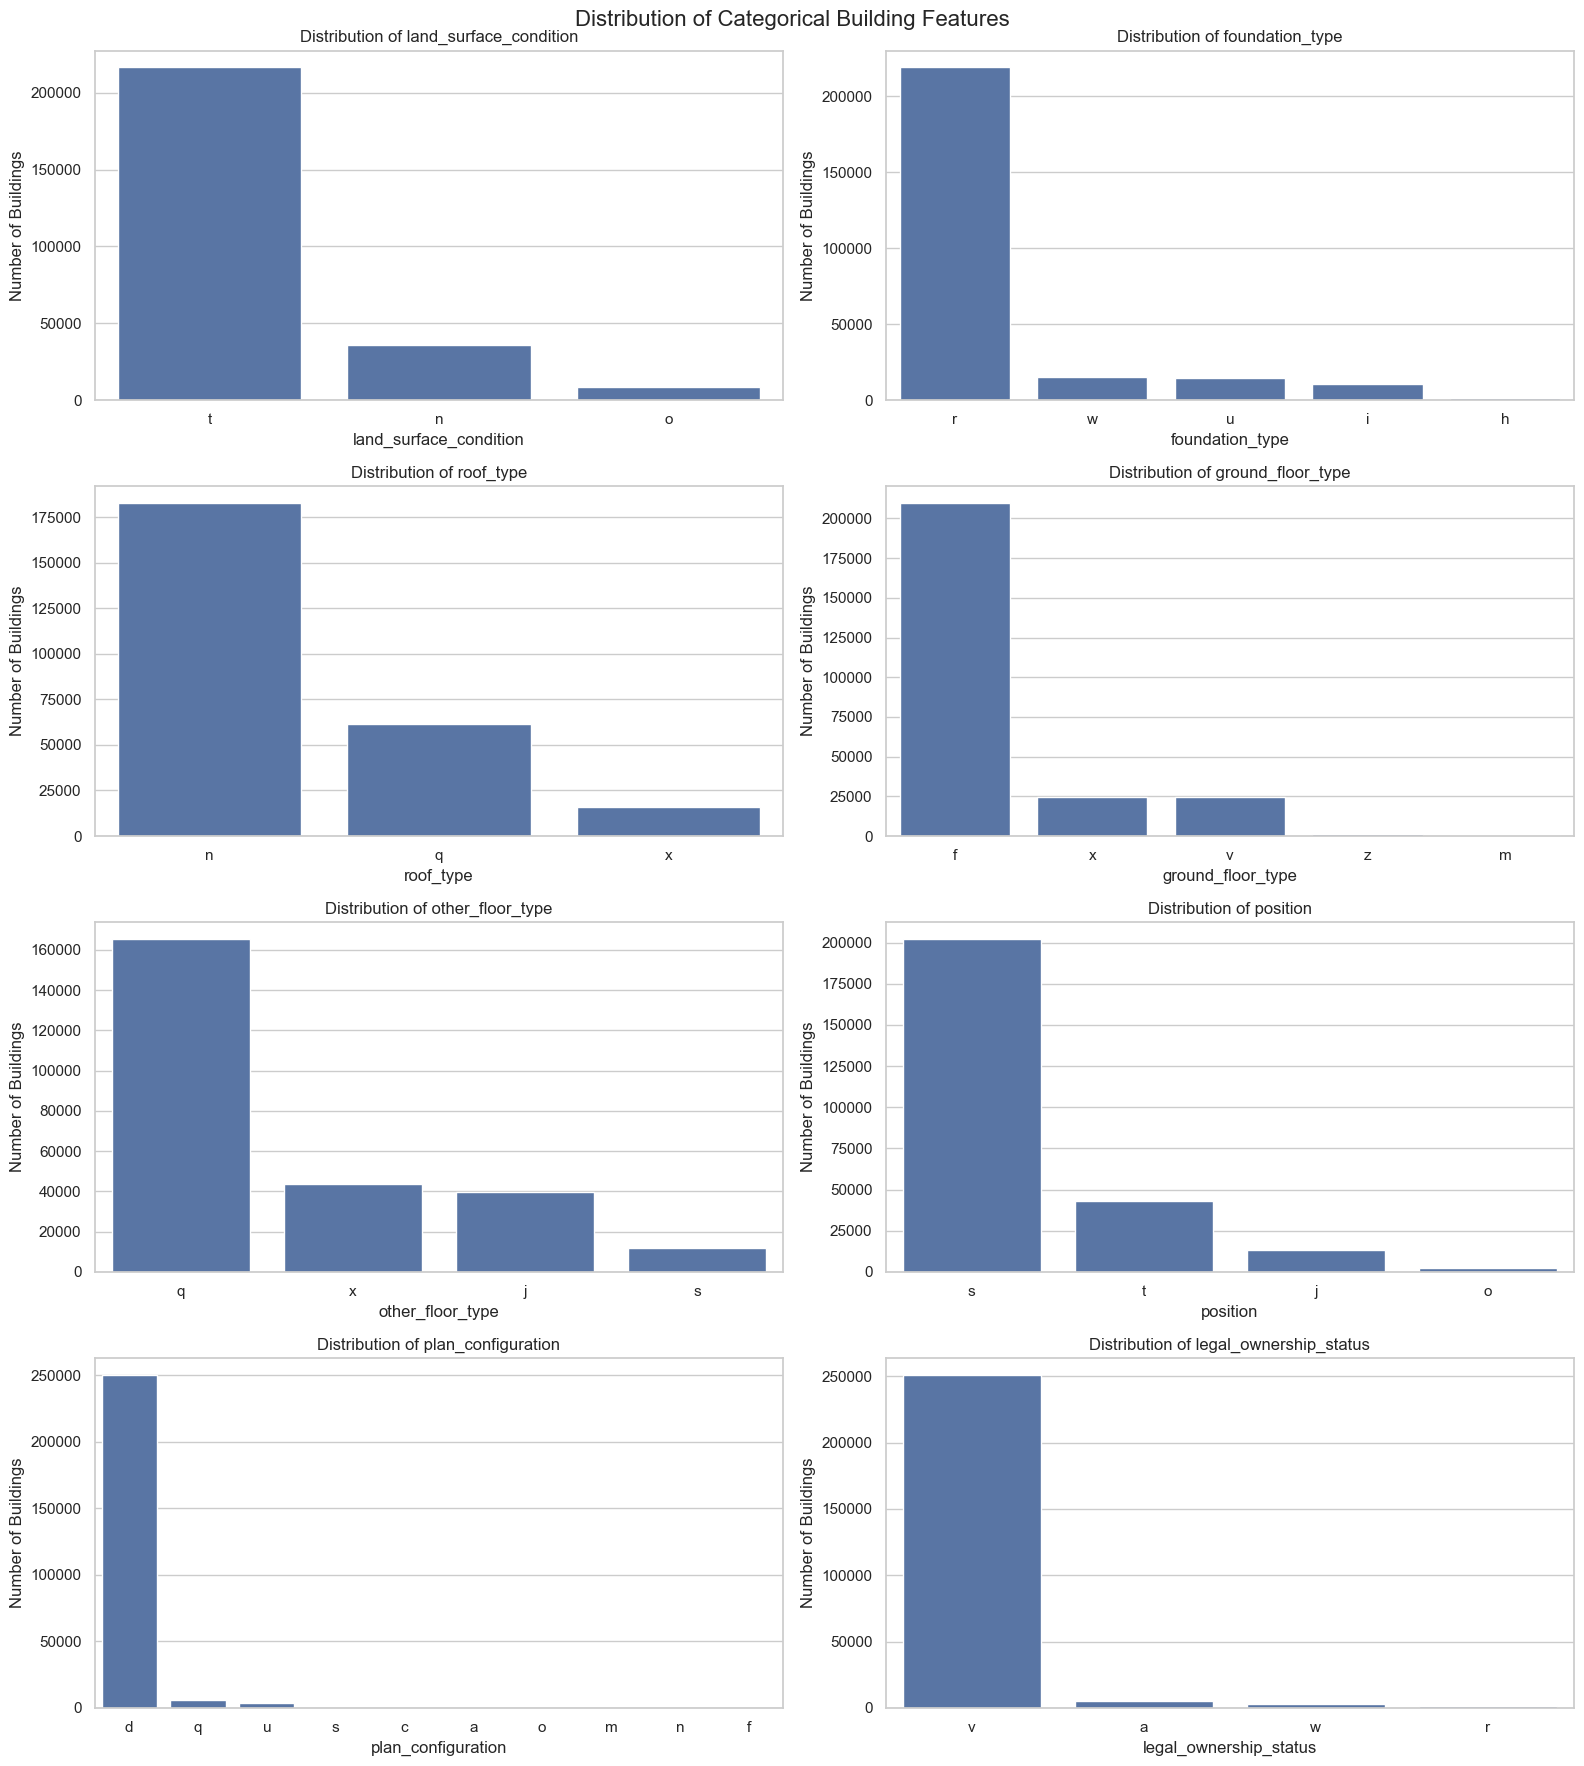

In [35]:
# Visualize the distribution of categorical features

fig, axes = plt.subplots(4, 2, figsize=(16, 18))

axes = axes.flatten()

for i, feature in enumerate(categorical_features):

    category_order = earthquake_df[feature].value_counts().index

    sns.countplot(
        data=earthquake_df,
        x=feature,
        order=category_order,
        ax=axes[i]
    )

    axes[i].set_title(f"Distribution of {feature}")
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel("Number of Buildings")
    axes[i].tick_params(axis="x", rotation=0)

plt.suptitle(
    "Distribution of Categorical Building Features",
    fontsize=16
)

plt.tight_layout()
plt.show()


## Phase 4 – Part 3: Categorical Feature Analysis

### Objective

The objective of this analysis is to understand the distribution of categorical building characteristics and identify the most frequently occurring categories.

### Features Selected

The following eight categorical features were selected:

1. land_surface_condition
2. foundation_type
3. roof_type
4. ground_floor_type
5. other_floor_type
6. position
7. plan_configuration
8. legal_ownership_status

### Analysis Techniques

- Identification of categorical columns.
- Calculation of unique category counts.
- Frequency distribution analysis.
- Percentage distribution analysis.
- Count plot visualizations.

The categorical values are encoded using letters. These values are treated as category labels rather than numerical measurements.



## Phase 4 – Part 4: Feature Relationship Analysis

### Objective

The objective of this analysis is to investigate the relationships between building characteristics and earthquake damage grades.

The target variable is `damage_grade`, which contains three ordered categories:

- Grade 1: Low damage
- Grade 2: Medium damage
- Grade 3: Almost complete destruction

### Analysis Approach

The analysis is divided into three parts:

1. Numerical features versus damage grade.
2. Categorical features versus damage grade.
3. Binary construction and secondary-use features versus damage grade.

Boxplots, grouped statistical summaries and proportion-based visualizations will be used to understand how building characteristics vary across damage categories.

The analysis will identify associations and patterns without assuming that any individual feature directly causes earthquake damage.


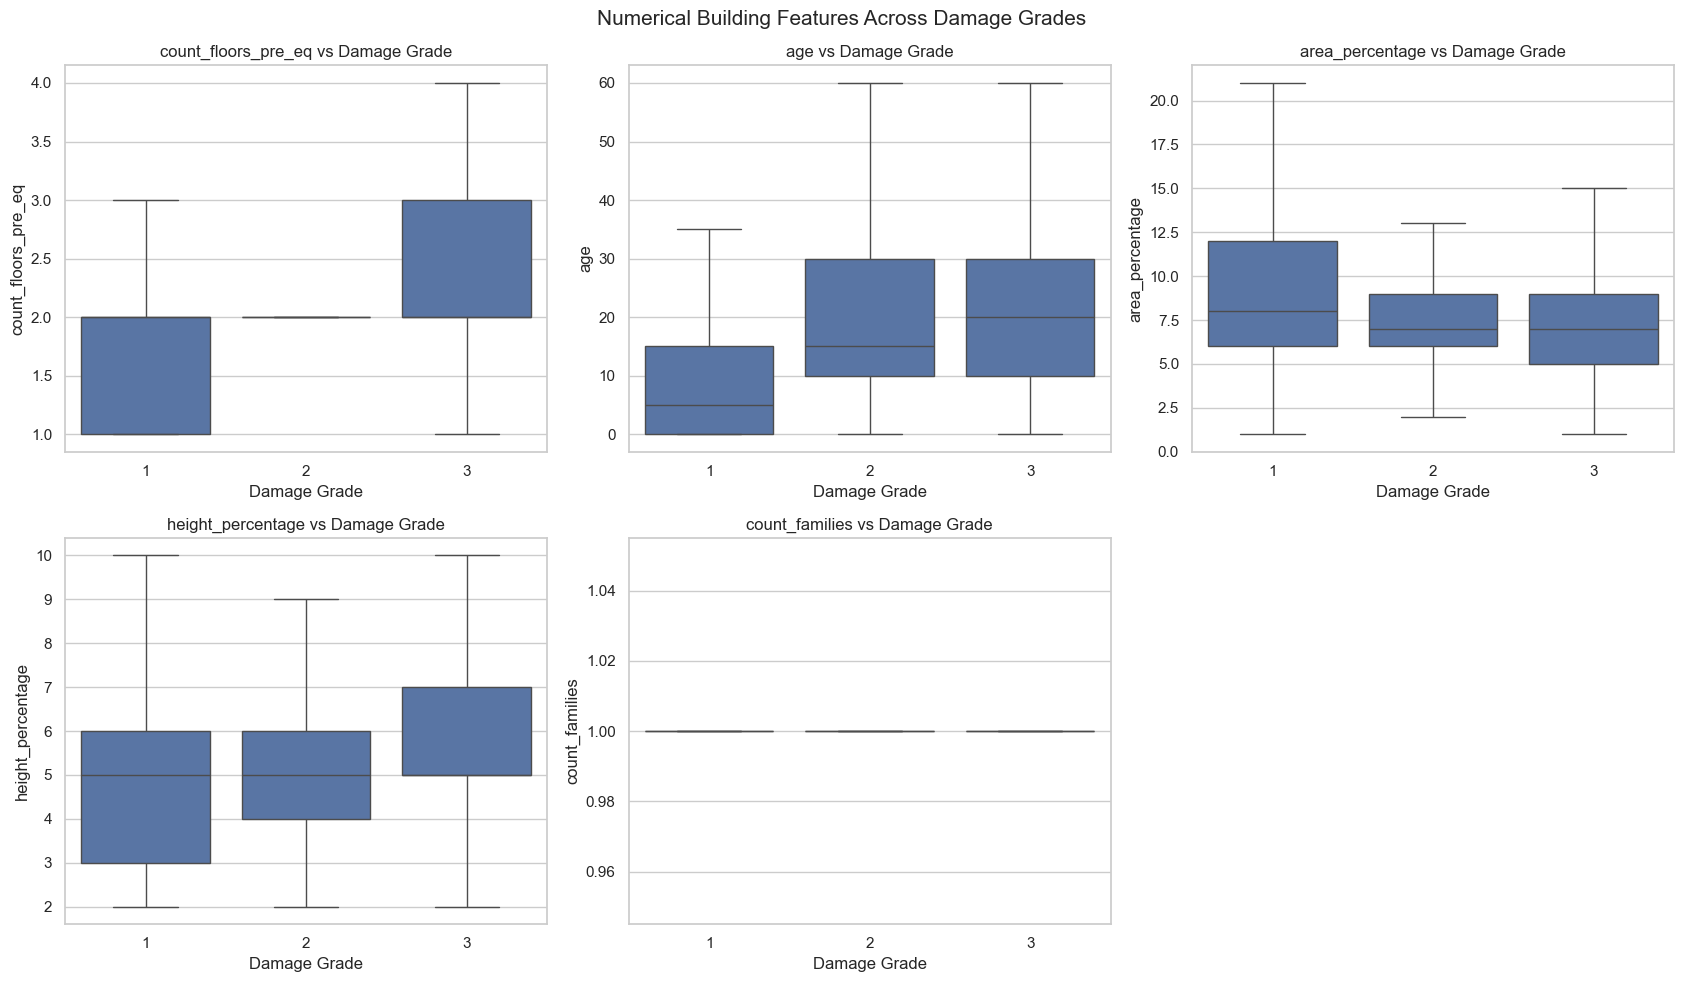

In [37]:
# Compare numerical building features across damage grades

fig, axes = plt.subplots(2, 3, figsize=(17, 10))

axes = axes.flatten()

for i, feature in enumerate(numeric_features):

    sns.boxplot(
        data=earthquake_df,
        x="damage_grade",
        y=feature,
        ax=axes[i],
        showfliers=False
    )

    axes[i].set_title(f"{feature} vs Damage Grade")
    axes[i].set_xlabel("Damage Grade")
    axes[i].set_ylabel(feature)

axes[5].set_visible(False)

plt.suptitle(
    "Numerical Building Features Across Damage Grades",
    fontsize=15
)

plt.tight_layout()
plt.show()

In [38]:
# Calculate mean and median for each numerical feature
# grouped by damage grade

damage_numeric_summary = (
    earthquake_df
    .groupby("damage_grade")[numeric_features]
    .agg(["mean", "median"])
)

display(damage_numeric_summary.round(2))

count_floors_pre_eq           age        area_percentage         \
                            mean median   mean median            mean median   
damage_grade                                                                   
1                           1.84    2.0  17.32    5.0            9.72    8.0   
2                           2.13    2.0  27.34   15.0            8.03    7.0   
3                           2.21    2.0  27.82   20.0            7.50    7.0   

             height_percentage        count_families         
                          mean median           mean median  
damage_grade                                                 
1                         5.15    5.0           0.92    1.0  
2                         5.43    5.0           0.98    1.0  
3                         5.52    5.0           1.01    1.0

In [39]:
# Compare building age statistics across damage grades

age_damage_summary = (
    earthquake_df
    .groupby("damage_grade")["age"]
    .agg(["count", "mean", "median", "min", "max"])
)

display(age_damage_summary.round(2))

,count,mean,median,min,max
damage_grade,,,,,
1,25124,17.32,5.0,0,995
2,148259,27.34,15.0,0,995
3,87218,27.82,20.0,0,995


In [40]:
# Calculate damage-grade percentages within each category

for feature in categorical_features:

    category_damage = pd.crosstab(
        earthquake_df[feature],
        earthquake_df["damage_grade"],
        normalize="index"
    ) * 100

    category_damage = category_damage.reindex(
        columns=[1, 2, 3],
        fill_value=0
    )

    print("\nFeature:", feature)
    print("-" * 55)

    category_damage.columns = [
        "Grade 1 (%)",
        "Grade 2 (%)",
        "Grade 3 (%)"
    ]

    display(category_damage.round(2))


Feature: land_surface_condition
-------------------------------------------------------


,Grade 1 (%),Grade 2 (%),Grade 3 (%)
land_surface_condition,,,
n,7.19,60.47,32.34
o,7.24,56.61,36.15
t,10.13,56.32,33.55



Feature: foundation_type
-------------------------------------------------------


,Grade 1 (%),Grade 2 (%),Grade 3 (%)
foundation_type,,,
h,24.72,39.99,35.29
i,56.75,41.16,2.09
r,4.89,57.26,37.85
u,25.87,59.89,14.24
w,28.79,61.32,9.89



Feature: roof_type
-------------------------------------------------------


,Grade 1 (%),Grade 2 (%),Grade 3 (%)
roof_type,,,
n,7.41,58.22,34.37
q,6.38,55.23,38.39
x,47.28,48.22,4.50


... (6 outputs left out)


Feature: plan_configuration
-------------------------------------------------------


,Grade 1 (%),Grade 2 (%),Grade 3 (%)
plan_configuration,,,
a,26.19,62.30,11.51
c,26.46,63.38,10.15
d,9.32,56.99,33.69
f,0.00,72.73,27.27
m,17.39,73.91,8.70
n,15.79,52.63,31.58
o,25.16,60.38,14.47
q,13.72,45.41,40.86
s,15.32,64.45,20.23



Feature: legal_ownership_status
-------------------------------------------------------


,Grade 1 (%),Grade 2 (%),Grade 3 (%)
legal_ownership_status,,,
a,27.41,55.77,16.82
r,14.46,49.36,36.18
v,9.27,57.05,33.68
w,4.86,48.71,46.43


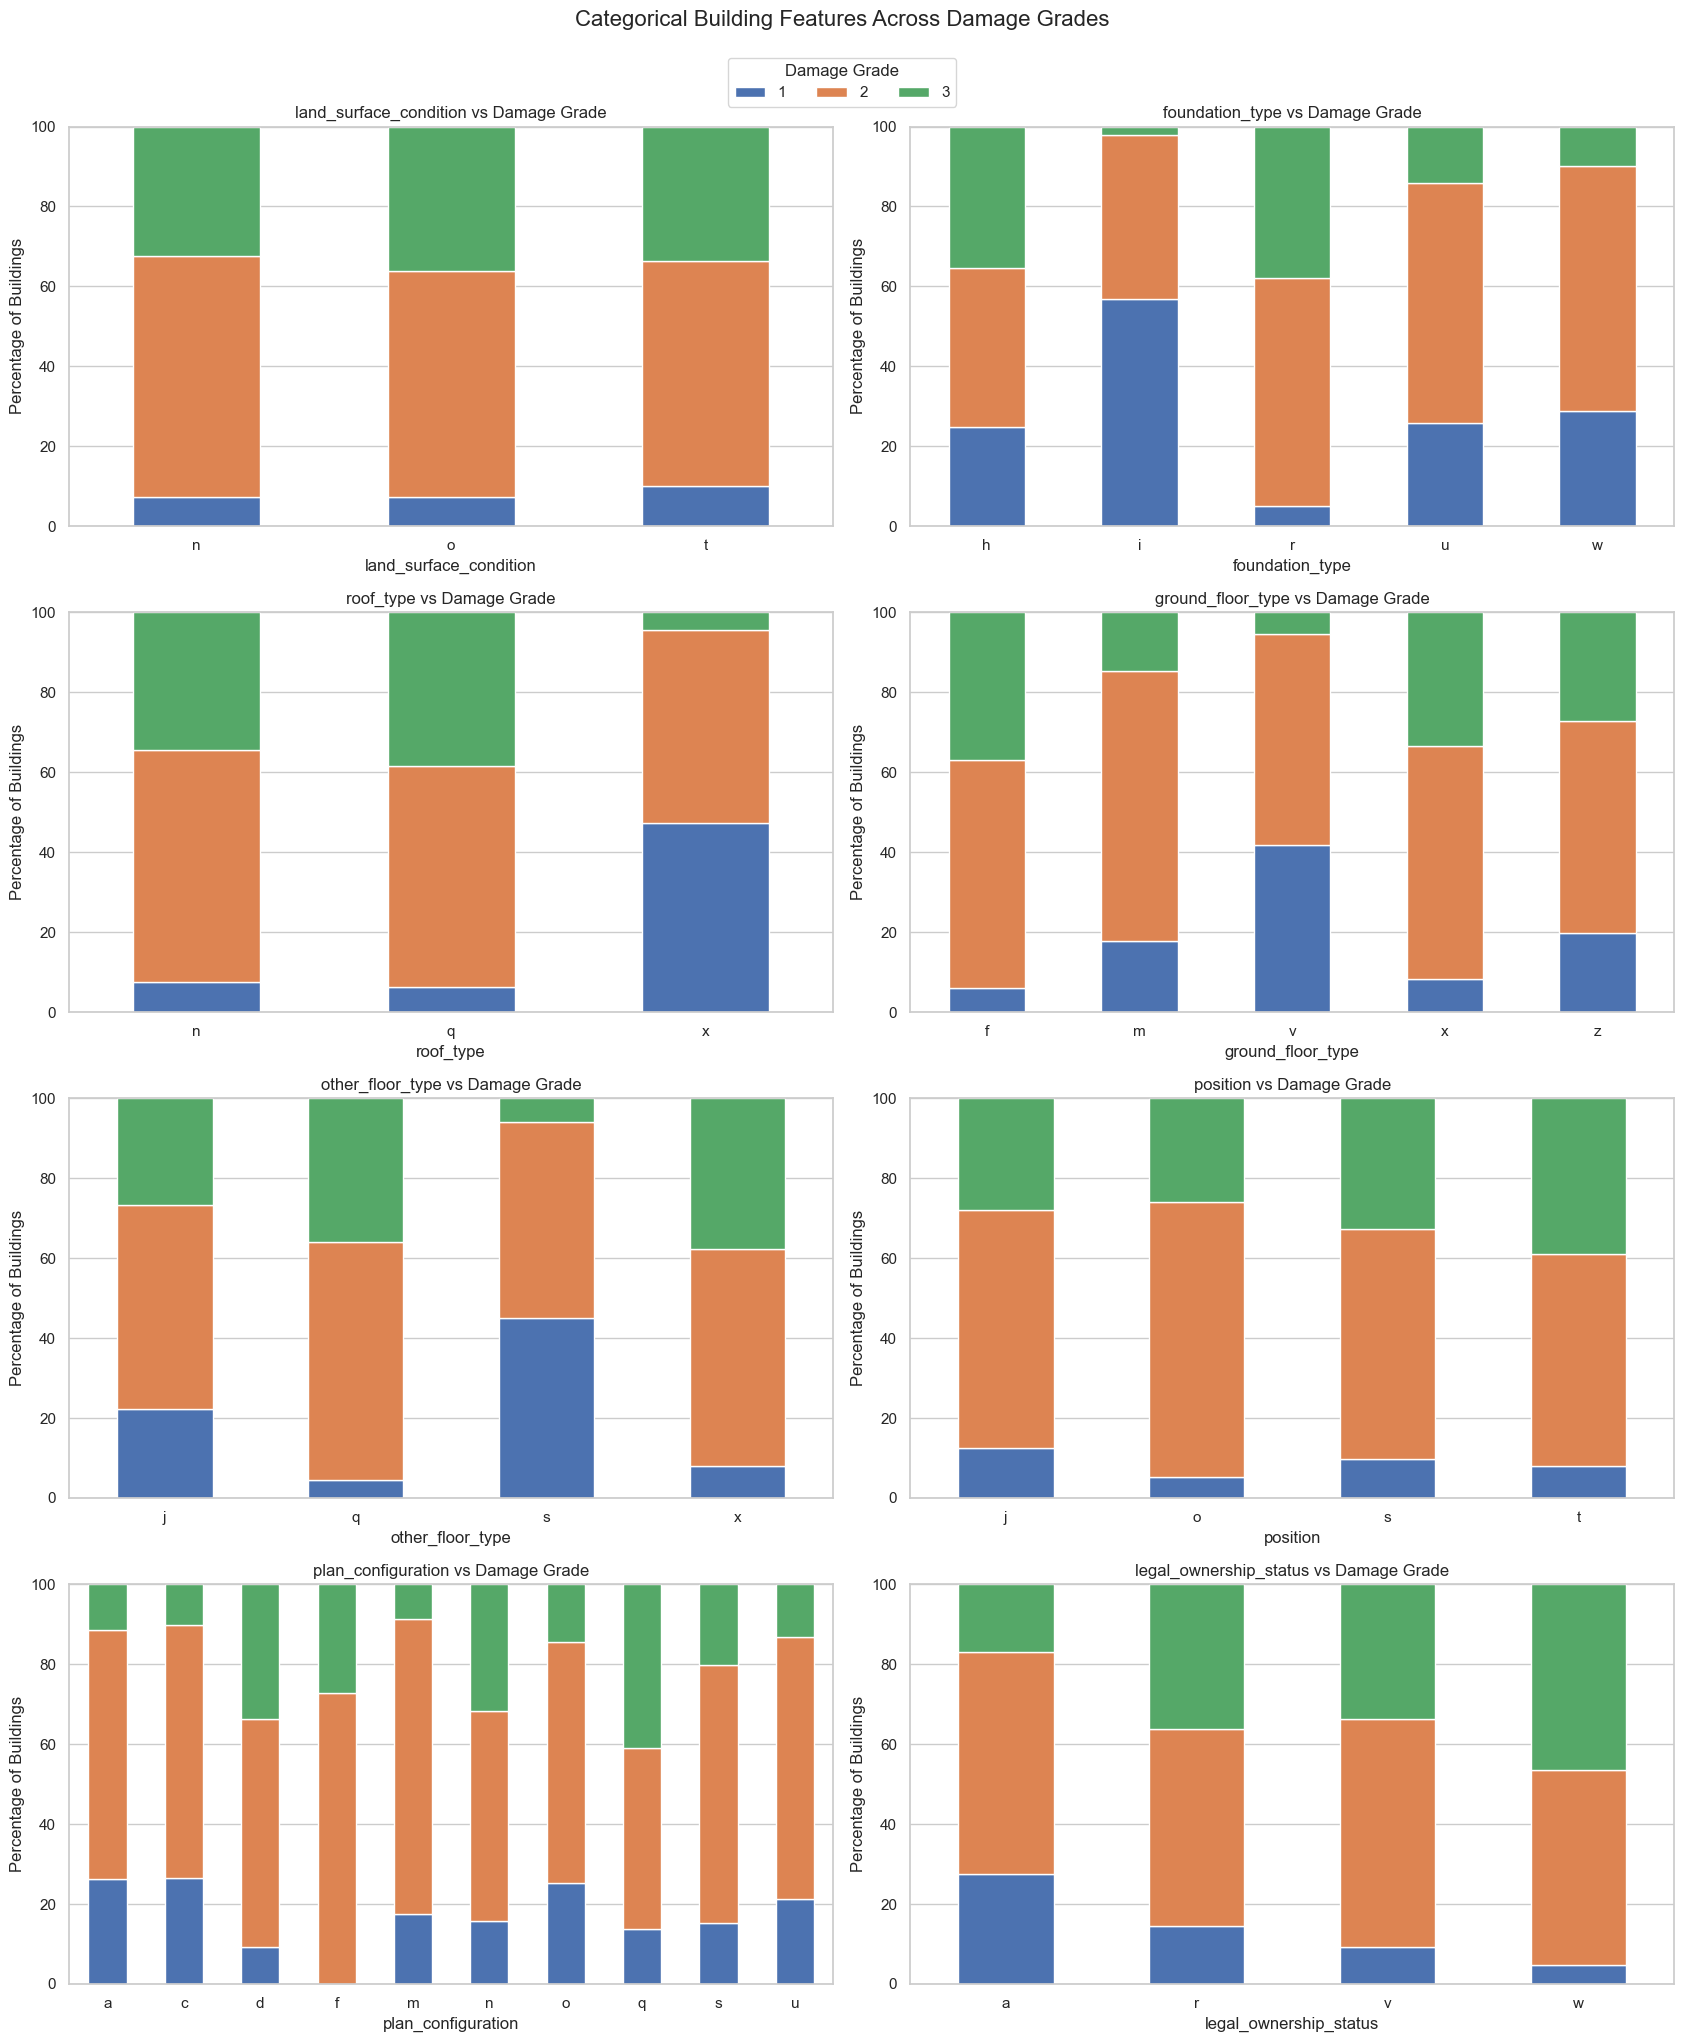

In [41]:
# Visualize damage-grade percentages within categorical features

fig, axes = plt.subplots(4, 2, figsize=(17, 20))

axes = axes.flatten()

for i, feature in enumerate(categorical_features):

    category_damage = pd.crosstab(
        earthquake_df[feature],
        earthquake_df["damage_grade"],
        normalize="index"
    ) * 100

    category_damage = category_damage.reindex(
        columns=[1, 2, 3],
        fill_value=0
    )

    ax = category_damage.plot(
        kind="bar",
        stacked=True,
        ax=axes[i],
        legend=False
    )

    ax.set_title(f"{feature} vs Damage Grade")
    ax.set_xlabel(feature)
    ax.set_ylabel("Percentage of Buildings")
    ax.set_ylim(0, 100)
    ax.tick_params(axis="x", rotation=0)

# Add a common legend
handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    title="Damage Grade",
    loc="upper center",
    ncol=3,
    bbox_to_anchor=(0.5, 1.0)
)

plt.suptitle(
    "Categorical Building Features Across Damage Grades",
    fontsize=16,
    y=1.02
)

plt.tight_layout()
plt.show()


## Phase 4 – Part 4: Feature Relationship Analysis

### A. Numerical Features versus Damage Grade

Boxplots were generated to compare numerical building characteristics across the three damage categories.

The analysis included:

- Number of floors.
- Building age.
- Building area percentage.
- Building height percentage.
- Number of families.

Grouped mean and median statistics were calculated to understand differences in numerical characteristics across damage grades.

### B. Categorical Features versus Damage Grade

The relationship between categorical building characteristics and damage grades was investigated using cross-tabulations and percentage-based stacked bar charts.

The analysis covered:

- Land surface condition.
- Foundation type.
- Roof type.
- Ground floor type.
- Other floor type.
- Building position.
- Plan configuration.
- Legal ownership status.

Damage-grade percentages were calculated within each category to make comparisons easier when category sizes differ.

### Conclusion

The numerical and categorical relationship analysis helps investigate which building characteristics are associated with different damage categories.

Final observations will be documented after examining the generated statistical summaries and visualizations.


In [43]:
# Identify binary features

binary_features = [
    column for column in train_values.columns
    if column.startswith("has_")
]

print("Binary Features:")
print(binary_features)

print("\nTotal Binary Features:", len(binary_features))

Binary Features:
['has_superstructure_adobe_mud', 'has_superstructure_mud_mortar_stone', 'has_superstructure_stone_flag', 'has_superstructure_cement_mortar_stone', 'has_superstructure_mud_mortar_brick', 'has_superstructure_cement_mortar_brick', 'has_superstructure_timber', 'has_superstructure_bamboo', 'has_superstructure_rc_non_engineered', 'has_superstructure_rc_engineered', 'has_superstructure_other', 'has_secondary_use', 'has_secondary_use_agriculture', 'has_secondary_use_hotel', 'has_secondary_use_rental', 'has_secondary_use_institution', 'has_secondary_use_school', 'has_secondary_use_industry', 'has_secondary_use_health_post', 'has_secondary_use_gov_office', 'has_secondary_use_use_police', 'has_secondary_use_other']

Total Binary Features: 22


In [44]:
# Calculate the frequency of 0 and 1 for each binary feature

for feature in binary_features:

    print("\nFeature:", feature)
    print("-" * 50)

    display(
        earthquake_df[feature]
        .value_counts()
        .sort_index()
        .rename_axis("Value")
        .reset_index(name="Building Count")
    )


Feature: has_superstructure_adobe_mud
--------------------------------------------------


,Value,Building Count
0,0,237500
1,1,23101



Feature: has_superstructure_mud_mortar_stone
--------------------------------------------------


,Value,Building Count
0,0,62040
1,1,198561



Feature: has_superstructure_stone_flag
--------------------------------------------------


,Value,Building Count
0,0,251654
1,1,8947


... (34 outputs left out)


Feature: has_secondary_use_use_police
--------------------------------------------------


,Value,Building Count
0,0,260578
1,1,23



Feature: has_secondary_use_other
--------------------------------------------------


,Value,Building Count
0,0,259267
1,1,1334


In [45]:
# Calculate the percentage of buildings having each characteristic

binary_summary = pd.DataFrame({
    "Present Count": earthquake_df[binary_features].sum(),
    "Absent Count": len(earthquake_df) - earthquake_df[binary_features].sum()
})

binary_summary["Present Percentage"] = (
    binary_summary["Present Count"] / len(earthquake_df)
) * 100

binary_summary = binary_summary.sort_values(
    by="Present Percentage",
    ascending=False
)

display(binary_summary.round(2))

,Present Count,Absent Count,Present Percentage
has_superstructure_mud_mortar_stone,198561,62040,76.19
has_superstructure_timber,66450,194151,25.50
has_secondary_use,29156,231445,11.19
has_superstructure_adobe_mud,23101,237500,8.86
has_superstructure_bamboo,22154,238447,8.50
has_superstructure_cement_mortar_brick,19615,240986,7.53
has_superstructure_mud_mortar_brick,17761,242840,6.82
has_secondary_use_agriculture,16777,243824,6.44
has_superstructure_rc_non_engineered,11099,249502,4.26
has_superstructure_stone_flag,8947,251654,3.43


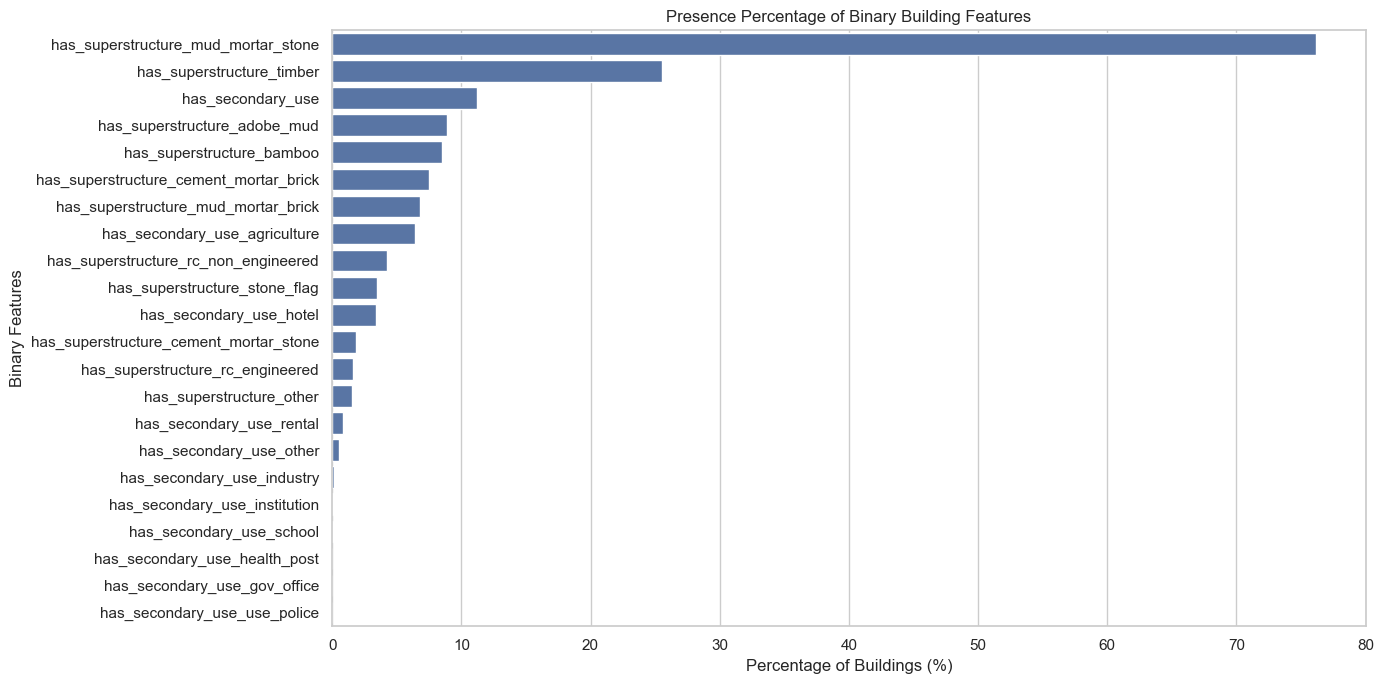

In [46]:
plt.figure(figsize=(14, 7))

sns.barplot(
    x=binary_summary["Present Percentage"],
    y=binary_summary.index
)

plt.title("Presence Percentage of Binary Building Features")
plt.xlabel("Percentage of Buildings (%)")
plt.ylabel("Binary Features")

plt.tight_layout()
plt.show()

In [47]:
# Calculate feature presence percentage within each damage grade

binary_damage_summary = (
    earthquake_df
    .groupby("damage_grade")[binary_features]
    .mean() * 100
)

display(binary_damage_summary.round(2))

,has_superstructure_adobe_mud,has_superstructure_mud_mortar_stone,has_superstructure_stone_flag,has_superstructure_cement_mortar_stone,has_superstructure_mud_mortar_brick,has_superstructure_cement_mortar_brick,has_superstructure_timber,has_superstructure_bamboo,has_superstructure_rc_non_engineered,has_superstructure_rc_engineered,has_superstructure_other,has_secondary_use,has_secondary_use_agriculture,has_secondary_use_hotel,has_secondary_use_rental,has_secondary_use_institution,has_secondary_use_school,has_secondary_use_industry,has_secondary_use_health_post,has_secondary_use_gov_office,has_secondary_use_use_police,has_secondary_use_other
damage_grade,,,,,,,,,,,,,,,,,,,,,,
1,2.36,34.87,0.72,3.30,2.48,28.28,30.42,11.30,15.35,10.57,2.61,16.91,3.30,8.82,3.49,0.39,0.12,0.23,0.05,0.05,0.02,0.70
2,9.38,76.86,3.06,2.19,7.89,7.70,27.11,9.44,3.93,0.95,1.52,11.95,7.20,3.41,0.71,0.09,0.03,0.10,0.02,0.01,0.01,0.57
3,9.87,86.97,4.85,0.77,6.24,1.25,21.35,6.09,1.62,0.09,1.15,8.25,6.04,1.71,0.21,0.02,0.02,0.08,0.01,0.00,0.01,0.35


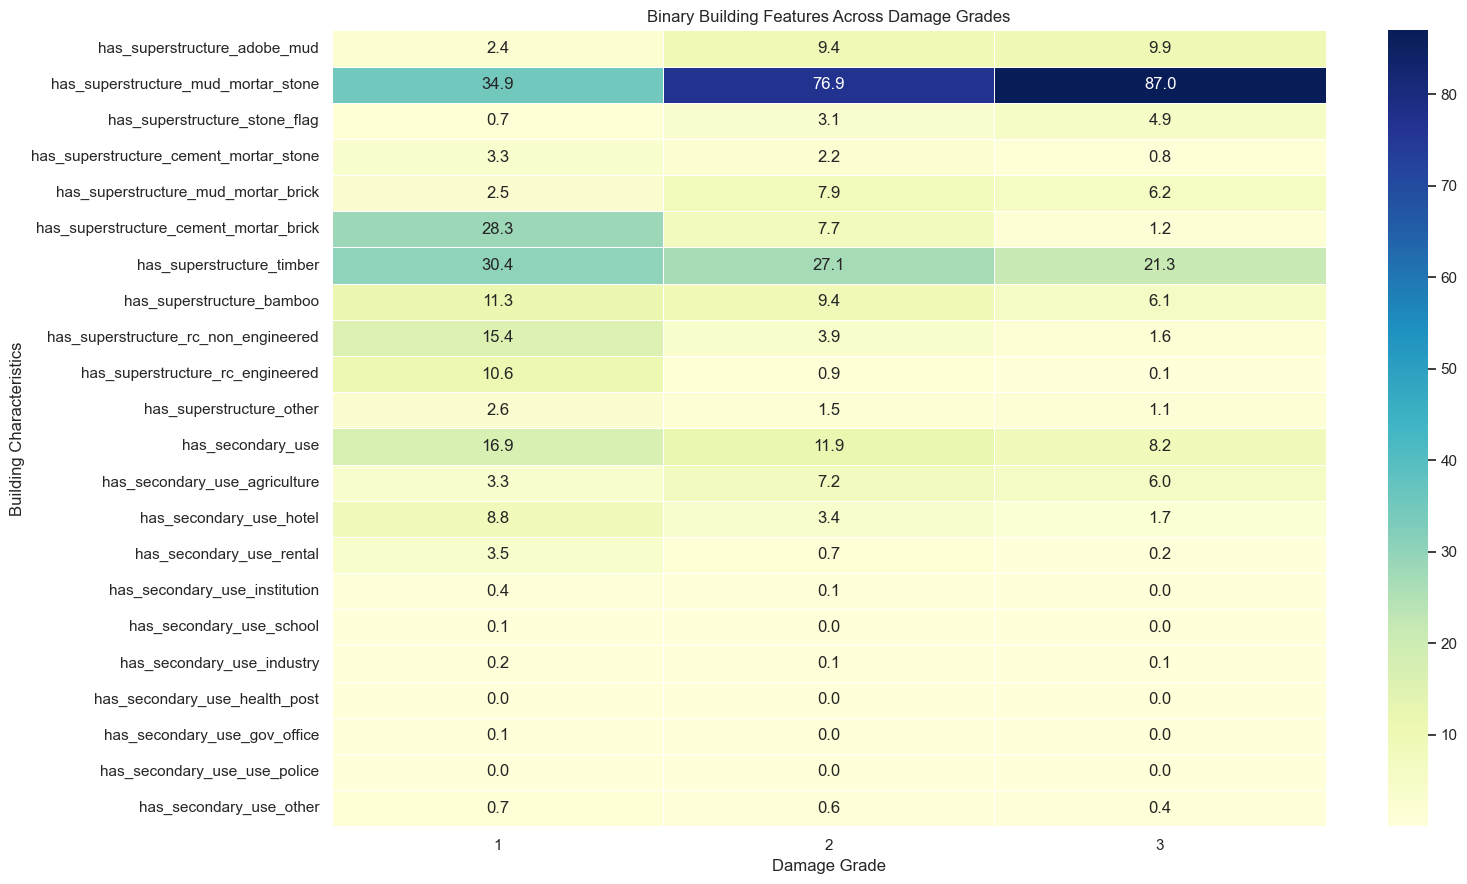

In [49]:
plt.figure(figsize=(16, 9))

sns.heatmap(
    binary_damage_summary.T,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    linewidths=0.5
)

plt.title("Binary Building Features Across Damage Grades")
plt.xlabel("Damage Grade")
plt.ylabel("Building Characteristics")

plt.tight_layout()
plt.show()

In [50]:
# Identify geographic features

geo_features = [
    "geo_level_1_id",
    "geo_level_2_id",
    "geo_level_3_id"
]

# Examine unique geographic regions

for feature in geo_features:

    print("\nFeature:", feature)
    print("-" * 50)

    print("Unique regions:", earthquake_df[feature].nunique())

    print("\nMost frequent regions:")

    display(
        earthquake_df[feature]
        .value_counts()
        .head(10)
    )


Feature: geo_level_1_id
--------------------------------------------------
Unique regions: 31

Most frequent regions:


geo_level_1_id
6     24381
26    22615
10    22079
17    21813
8     19080
7     18994
20    17216
21    14889
4     14568
27    12532
Name: count, dtype: int64


Feature: geo_level_2_id
--------------------------------------------------
Unique regions: 1414

Most frequent regions:


geo_level_2_id
39      4038
158     2520
181     2080
1387    2040
157     1897
363     1760
463     1740
673     1704
533     1684
883     1626
Name: count, dtype: int64


Feature: geo_level_3_id
--------------------------------------------------
Unique regions: 11595

Most frequent regions:


geo_level_3_id
633      651
9133     647
621      530
11246    470
2005     466
11440    455
7723     443
9229     381
2452     349
12258    312
Name: count, dtype: int64

In [52]:
# Calculate damage-grade distribution by major geographic region

geo_damage_summary = pd.crosstab(
    earthquake_df["geo_level_1_id"],
    earthquake_df["damage_grade"],
    normalize="index"
) * 100

geo_damage_summary.columns = [
    "Grade 1 (%)",
    "Grade 2 (%)",
    "Grade 3 (%)"
]

display(geo_damage_summary.round(2))

,Grade 1 (%),Grade 2 (%),Grade 3 (%)
geo_level_1_id,,,
0,8.40,76.66,14.93
1,15.22,73.49,11.29
2,9.13,65.52,25.35
3,3.25,60.34,36.41
4,3.58,76.63,19.79
5,16.58,74.87,8.55
6,8.65,66.54,24.82
7,5.44,59.35,35.21
8,3.43,44.62,51.95


<Figure size 1600x800 with 0 Axes>

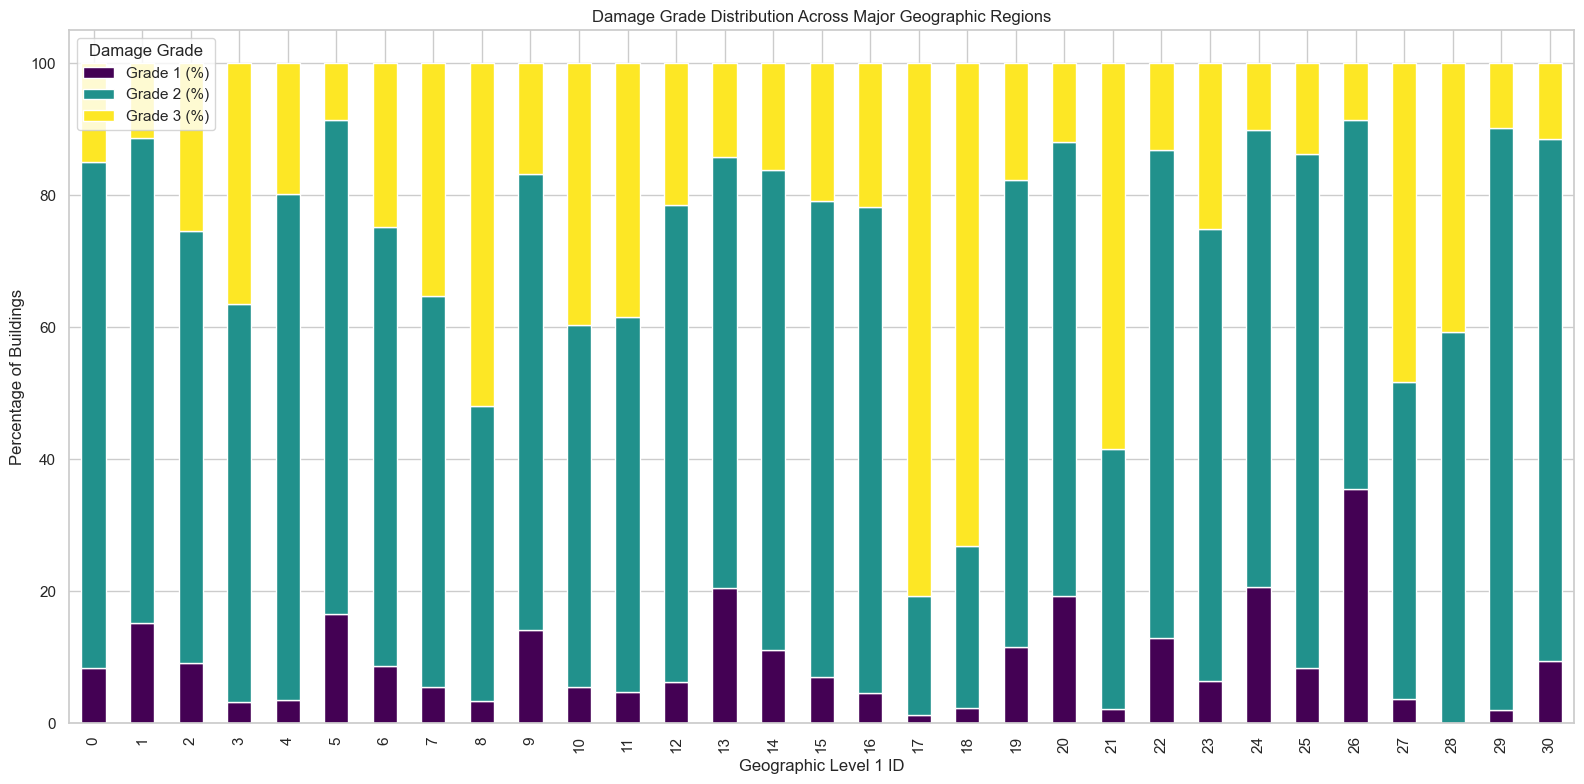

In [53]:
plt.figure(figsize=(16, 8))

geo_damage_summary.plot(
    kind="bar",
    stacked=True,
    figsize=(16, 8),
    colormap="viridis"
)

plt.title("Damage Grade Distribution Across Major Geographic Regions")
plt.xlabel("Geographic Level 1 ID")
plt.ylabel("Percentage of Buildings")
plt.legend(title="Damage Grade")

plt.tight_layout()
plt.show()


## Phase 4 – Part 5 and Part 6: Binary and Geographic Feature Analysis

### 1. Binary Feature Analysis

The binary features were identified using their column names and their frequency distributions were examined.

The features represent the presence or absence of building construction materials and secondary uses.

Presence percentages were calculated to understand the frequency of each characteristic in the dataset.

### 2. Binary Features versus Damage Grade

The percentage of buildings having each binary characteristic was compared across the three damage grades.

A heatmap was generated to visualize differences in feature prevalence between damage categories.

### 3. Geographic Feature Analysis

Three geographic identifiers were examined:

- `geo_level_1_id`
- `geo_level_2_id`
- `geo_level_3_id`

The number of unique geographic regions and their most frequent categories were investigated.

### 4. Regional Damage Distribution

The relationship between major geographic regions and damage grades was analyzed using percentage-based cross-tabulation and stacked bar charts.

### Conclusion

Binary and geographic feature analysis provides additional information about building construction characteristics and regional differences in observed damage grades.

These analyses help identify patterns that can be investigated further during feature engineering and model development.


In [55]:
print("1. BINARY FEATURE DISTRIBUTION")
display(binary_summary.round(2))

print("\n2. BINARY FEATURES BY DAMAGE GRADE")
display(binary_damage_summary.round(2))

print("\n3. GEOGRAPHIC REGION COUNTS")

for feature in geo_features:
    print(feature, ":", earthquake_df[feature].nunique())

print("\n4. DAMAGE DISTRIBUTION BY MAJOR REGION")
display(geo_damage_summary.head(10).round(2))

1. BINARY FEATURE DISTRIBUTION


,Present Count,Absent Count,Present Percentage
has_superstructure_mud_mortar_stone,198561,62040,76.19
has_superstructure_timber,66450,194151,25.50
has_secondary_use,29156,231445,11.19
has_superstructure_adobe_mud,23101,237500,8.86
has_superstructure_bamboo,22154,238447,8.50
has_superstructure_cement_mortar_brick,19615,240986,7.53
has_superstructure_mud_mortar_brick,17761,242840,6.82
has_secondary_use_agriculture,16777,243824,6.44
has_superstructure_rc_non_engineered,11099,249502,4.26
has_superstructure_stone_flag,8947,251654,3.43



2. BINARY FEATURES BY DAMAGE GRADE


,has_superstructure_adobe_mud,has_superstructure_mud_mortar_stone,has_superstructure_stone_flag,has_superstructure_cement_mortar_stone,has_superstructure_mud_mortar_brick,has_superstructure_cement_mortar_brick,has_superstructure_timber,has_superstructure_bamboo,has_superstructure_rc_non_engineered,has_superstructure_rc_engineered,has_superstructure_other,has_secondary_use,has_secondary_use_agriculture,has_secondary_use_hotel,has_secondary_use_rental,has_secondary_use_institution,has_secondary_use_school,has_secondary_use_industry,has_secondary_use_health_post,has_secondary_use_gov_office,has_secondary_use_use_police,has_secondary_use_other
damage_grade,,,,,,,,,,,,,,,,,,,,,,
1,2.36,34.87,0.72,3.30,2.48,28.28,30.42,11.30,15.35,10.57,2.61,16.91,3.30,8.82,3.49,0.39,0.12,0.23,0.05,0.05,0.02,0.70
2,9.38,76.86,3.06,2.19,7.89,7.70,27.11,9.44,3.93,0.95,1.52,11.95,7.20,3.41,0.71,0.09,0.03,0.10,0.02,0.01,0.01,0.57
3,9.87,86.97,4.85,0.77,6.24,1.25,21.35,6.09,1.62,0.09,1.15,8.25,6.04,1.71,0.21,0.02,0.02,0.08,0.01,0.00,0.01,0.35



3. GEOGRAPHIC REGION COUNTS
geo_level_1_id : 31
geo_level_2_id : 1414
geo_level_3_id : 11595

4. DAMAGE DISTRIBUTION BY MAJOR REGION


,Grade 1 (%),Grade 2 (%),Grade 3 (%)
geo_level_1_id,,,
0,8.40,76.66,14.93
1,15.22,73.49,11.29
2,9.13,65.52,25.35
3,3.25,60.34,36.41
4,3.58,76.63,19.79
5,16.58,74.87,8.55
6,8.65,66.54,24.82
7,5.44,59.35,35.21
8,3.43,44.62,51.95



# Phase 5 – Feature Engineering and Data Preprocessing

## 5.1 Objective

The objective of this phase is to prepare the earthquake building dataset for Machine Learning by organizing features, handling different data types and applying appropriate preprocessing techniques.

## 5.2 Feature Categories

The dataset contains the following feature groups:

1. Numerical features – Building age, number of floors, area percentage, height percentage and number of families.
2. Categorical features – Foundation type, roof type, ground-floor type, land-surface condition and other categorical characteristics.
3. Binary features – Construction material indicators and secondary-use indicators.
4. Geographic features – Geographic level 1, level 2 and level 3 identifiers.

## 5.3 Preprocessing Objectives

- Separate independent variables and the target variable.
- Exclude the unique building identifier from predictive features.
- Identify appropriate encoding techniques for categorical variables.
- Evaluate whether numerical feature scaling is required.
- Investigate class imbalance in the target variable.
- Prepare preprocessing pipelines for Machine Learning models.
- Prevent data leakage by fitting preprocessing steps only on training data.

## 5.4 Expected Outcome

Prepare clean and appropriately transformed input features and target labels for building classification models.


In [58]:
# Organize features into their respective groups

feature_groups = {
    "Numerical": numeric_features,
    "Categorical": categorical_features,
    "Binary": binary_features,
    "Geographic": geo_features
}

# Display feature counts
for group, features in feature_groups.items():

    print(f"{group} Features: {len(features)}")

    print(features)
    print("-" * 60)

# Combine all predictive feature names
all_grouped_features = [
    feature
    for features in feature_groups.values()
    for feature in features
]

# Check overlapping feature assignments
duplicate_assignments = [
    feature for feature in set(all_grouped_features)
    if all_grouped_features.count(feature) > 1
]

# Find features that have not been assigned to a group
unclassified_features = [
    feature
    for feature in train_values.columns
    if feature != "building_id"
    and feature not in all_grouped_features
]

print("Total predictive features:", len(all_grouped_features))
print("Duplicate assignments:", duplicate_assignments)
print("Unclassified features:", unclassified_features)

Numerical Features: 5
['count_floors_pre_eq', 'age', 'area_percentage', 'height_percentage', 'count_families']
------------------------------------------------------------
Categorical Features: 8
['land_surface_condition', 'foundation_type', 'roof_type', 'ground_floor_type', 'other_floor_type', 'position', 'plan_configuration', 'legal_ownership_status']
------------------------------------------------------------
Binary Features: 22
['has_superstructure_adobe_mud', 'has_superstructure_mud_mortar_stone', 'has_superstructure_stone_flag', 'has_superstructure_cement_mortar_stone', 'has_superstructure_mud_mortar_brick', 'has_superstructure_cement_mortar_brick', 'has_superstructure_timber', 'has_superstructure_bamboo', 'has_superstructure_rc_non_engineered', 'has_superstructure_rc_engineered', 'has_superstructure_other', 'has_secondary_use', 'has_secondary_use_agriculture', 'has_secondary_use_hotel', 'has_secondary_use_rental', 'has_secondary_use_institution', 'has_secondary_use_school', 'ha

In [57]:
# Separate input features and target variable

X = earthquake_df.drop(
    columns=["building_id", "damage_grade"]
)

y = earthquake_df["damage_grade"]

print("Input Features (X):", X.shape)
print("Target Variable (y):", y.shape)

Input Features (X): (260601, 38)
Target Variable (y): (260601,)


In [59]:
print("Input Feature Information")

print("Number of rows:", X.shape[0])
print("Number of columns:", X.shape[1])

print("\nTarget Variable Information")

print("Number of rows:", y.shape[0])
print("Target classes:", sorted(y.unique()))

print("\nTarget Distribution")

display(y.value_counts().sort_index())

Input Feature Information
Number of rows: 260601
Number of columns: 38

Target Variable Information
Number of rows: 260601
Target classes: [np.int64(1), np.int64(2), np.int64(3)]

Target Distribution


damage_grade
1     25124
2    148259
3     87218
Name: count, dtype: int64


## Phase 5 – Part 1: Feature Identification and Separation

### Observations

1. The original dataset contains 39 columns, including the unique building identifier.

2. The 38 predictive features were organized into four groups:
   - 5 numerical features.
   - 8 categorical features.
   - 22 binary features.
   - 3 geographic features.

3. No overlapping or unclassified predictive features were expected after feature-group verification.

4. The `building_id` column was excluded from the model inputs because it serves as a unique identifier rather than a meaningful predictive characteristic.

5. The target variable `damage_grade` was separated from the independent features.

6. The resulting input dataset contains 260,601 records and 38 features, while the target contains 260,601 damage-grade labels.

### Conclusion

The dataset was successfully organized into independent features and a dependent target variable. The next step is to prepare the different feature types for Machine Learning using appropriate preprocessing techniques.



## Phase 5 – Part 2: Train, Validation and Test Splitting

### Objective

The dataset is divided into training, validation and test subsets to evaluate model performance reliably.

### Splitting Strategy

A stratified splitting technique is used to preserve the distribution of all three damage grades across the subsets.

The selected proportions are:

- Training: 70%
- Validation: 15%
- Testing: 15%

### Purpose of Each Subset

**Training Dataset:**
Used to train machine learning algorithms and learn patterns from building characteristics.

**Validation Dataset:**
Used to compare model performance, tune hyperparameters and select the best candidate model.

**Test Dataset:**
Reserved for the final independent evaluation of the selected model.

### Data Leakage Prevention

Preprocessing transformations such as feature scaling and categorical encoding will be fitted using only the training dataset and subsequently applied to the validation and test datasets.

This prevents information from the validation and test data from influencing the fitted preprocessing transformations.

### Expected Outcome

Three separate datasets will be created while preserving the proportions of damage grades 1, 2 and 3.


In [61]:
from sklearn.model_selection import train_test_split

In [62]:
# First split: 70% training and 30% temporary data

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Temporary Features:", X_temp.shape)

print("Training Target:", y_train.shape)
print("Temporary Target:", y_temp.shape)

Training Features: (182420, 38)
Temporary Features: (78181, 38)
Training Target: (182420,)
Temporary Target: (78181,)


In [63]:
# Second split: Divide the temporary data equally

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training Data:", X_train.shape, y_train.shape)
print("Validation Data:", X_val.shape, y_val.shape)
print("Testing Data:", X_test.shape, y_test.shape)

Training Data: (182420, 38) (182420,)
Validation Data: (39090, 38) (39090,)
Testing Data: (39091, 38) (39091,)


In [65]:
# Compare class counts across datasets

split_counts = pd.DataFrame({
    "Original": y.value_counts().sort_index(),
    "Training": y_train.value_counts().sort_index(),
    "Validation": y_val.value_counts().sort_index(),
    "Testing": y_test.value_counts().sort_index()
})

display(split_counts)

,Original,Training,Validation,Testing
damage_grade,,,,
1,25124,17587,3768,3769
2,148259,103781,22239,22239
3,87218,61052,13083,13083


In [66]:
# Compare damage-grade percentages across datasets

split_percentages = (
    split_counts.div(split_counts.sum(axis=0), axis=1) * 100
)

display(split_percentages.round(2))

,Original,Training,Validation,Testing
damage_grade,,,,
1,9.64,9.64,9.64,9.64
2,56.89,56.89,56.89,56.89
3,33.47,33.47,33.47,33.47


In [67]:
# Check overlap between training, validation and test records

train_indices = set(X_train.index)
validation_indices = set(X_val.index)
test_indices = set(X_test.index)

print(
    "Training-Validation Overlap:",
    len(train_indices.intersection(validation_indices))
)

print(
    "Training-Test Overlap:",
    len(train_indices.intersection(test_indices))
)

print(
    "Validation-Test Overlap:",
    len(validation_indices.intersection(test_indices))
)

Training-Validation Overlap: 0
Training-Test Overlap: 0
Validation-Test Overlap: 0



## Phase 5 – Part 2: Train, Validation and Test Splitting

### Observations

1. The complete dataset was divided into training, validation and test subsets using stratified sampling.

2. The training subset contains approximately 70% of the records.

3. The validation and test subsets each contain approximately 15% of the records.

4. Stratification was applied using the `damage_grade` target variable to preserve the distribution of the three damage categories.

5. The class distributions were compared across all three subsets to verify that the original target proportions were maintained.

6. The original DataFrame indices were checked to ensure that no records overlapped between training, validation and test datasets.

### Conclusion

The dataset was successfully divided into three independent subsets.

The training dataset will be used for model fitting, the validation dataset for model selection and hyperparameter tuning, and the test dataset will remain reserved for final model evaluation.

All preprocessing transformations will be fitted using the training data only to prevent data leakage.



## Phase 5 – Part 3: Feature Encoding and Transformation

### Objective

The objective of this phase is to transform the different feature types into suitable numerical representations for machine learning algorithms.

### 1. Numerical Feature Scaling

StandardScaler will be used to standardize numerical features by removing the mean and scaling them to unit variance.

### 2. Categorical Feature Encoding

One-Hot Encoding will be applied to categorical features to convert their categories into numerical indicator columns.

### 3. Geographic Feature Encoding

Geographic identifiers will be treated as categorical variables rather than continuous numerical measurements.

One-Hot Encoding with infrequent-category grouping will be investigated to control the dimensionality created by high-cardinality geographic features.

### 4. Binary Feature Handling

Binary features already contain 0 and 1 values. They will be retained without additional encoding.

### 5. Preprocessing Pipeline

A ColumnTransformer will combine the different preprocessing techniques into a single pipeline.

The preprocessing transformations will be fitted using only the training dataset and subsequently applied to validation and test datasets.

This helps prevent data leakage.


In [68]:
# Combine categorical and geographic features

encoding_features = categorical_features + geo_features

# Calculate unique category counts

cardinality_summary = pd.DataFrame({
    "Feature": encoding_features,
    "Unique Categories": [
        X_train[feature].nunique()
        for feature in encoding_features
    ]
})

display(
    cardinality_summary.sort_values(
        by="Unique Categories",
        ascending=False
    ).reset_index(drop=True)
)

,Feature,Unique Categories
0,geo_level_3_id,11227
1,geo_level_2_id,1404
2,geo_level_1_id,31
3,plan_configuration,10
4,foundation_type,5
5,ground_floor_type,5
6,other_floor_type,4
7,position,4
8,legal_ownership_status,4
9,land_surface_condition,3


In [69]:
# Examine how frequently geographic categories occur

for feature in geo_features:

    category_counts = X_train[feature].value_counts()

    print("\nGeographic Feature:", feature)
    print("-" * 50)

    print("Total unique categories:", len(category_counts))

    print("Categories occurring fewer than 50 times:",
          (category_counts < 50).sum())

    print("Categories occurring at least 50 times:",
          (category_counts >= 50).sum())

    print("Least frequent category count:",
          category_counts.min())

    print("Most frequent category count:",
          category_counts.max())


Geographic Feature: geo_level_1_id
--------------------------------------------------
Total unique categories: 31
Categories occurring fewer than 50 times: 0
Categories occurring at least 50 times: 31
Least frequent category count: 184
Most frequent category count: 17070

Geographic Feature: geo_level_2_id
--------------------------------------------------
Total unique categories: 1404
Categories occurring fewer than 50 times: 561
Categories occurring at least 50 times: 843
Least frequent category count: 1
Most frequent category count: 2800

Geographic Feature: geo_level_3_id
--------------------------------------------------
Total unique categories: 11227
Categories occurring fewer than 50 times: 10659
Categories occurring at least 50 times: 568
Least frequent category count: 1
Most frequent category count: 461


In [70]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

print("Preprocessing libraries imported successfully.")

Preprocessing libraries imported successfully.


In [71]:
# Numerical feature transformer

numeric_transformer = StandardScaler()

# Categorical feature transformer

categorical_transformer = OneHotEncoder(
    handle_unknown="ignore"
)

# Geographic feature transformer

geographic_transformer = OneHotEncoder(
    handle_unknown="ignore",
    min_frequency=50
)

# Binary feature transformer

binary_transformer = "passthrough"

In [72]:
# Combine all feature-specific preprocessing steps

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),

        ("cat", categorical_transformer, categorical_features),

        ("geo", geographic_transformer, geo_features),

        ("binary", binary_transformer, binary_features)
    ],
    remainder="drop"
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [73]:
# Fit transformations using training data only

X_train_processed = preprocessor.fit_transform(X_train)

# Apply learned transformations to validation and test data

X_val_processed = preprocessor.transform(X_val)

X_test_processed = preprocessor.transform(X_test)

print("Preprocessing completed successfully.")

Preprocessing completed successfully.


In [74]:
print("Original Training Shape:", X_train.shape)
print("Processed Training Shape:", X_train_processed.shape)

print("\nOriginal Validation Shape:", X_val.shape)
print("Processed Validation Shape:", X_val_processed.shape)

print("\nOriginal Testing Shape:", X_test.shape)
print("Processed Testing Shape:", X_test_processed.shape)

Original Training Shape: (182420, 38)
Processed Training Shape: (182420, 1509)

Original Validation Shape: (39090, 38)
Processed Validation Shape: (39090, 1509)

Original Testing Shape: (39091, 38)
Processed Testing Shape: (39091, 1509)


In [75]:
from scipy import sparse

print("Training output type:", type(X_train_processed))

if sparse.issparse(X_train_processed):

    print("Sparse matrix detected.")

    print("Number of non-zero values:",
          X_train_processed.nnz)

    density = (
        X_train_processed.nnz /
        (X_train_processed.shape[0] * X_train_processed.shape[1])
    )

    print("Matrix density:", round(density * 100, 4), "%")

else:

    print("Dense matrix detected.")

Training output type: <class 'scipy.sparse._csr.csr_matrix'>
Sparse matrix detected.
Number of non-zero values: 3225787
Matrix density: 1.1719 %


In [76]:
from sklearn.utils.class_weight import compute_class_weight

# Identify the classes in the training dataset

classes = np.unique(y_train)

# Calculate balanced class weights

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = dict(zip(classes, weights))

print("Class Weights:")

for grade, weight in class_weights.items():

    print(f"Damage Grade {grade}: {weight:.4f}")

Class Weights:
Damage Grade 1: 3.4575
Damage Grade 2: 0.5859
Damage Grade 3: 0.9960



## Phase 5 – Part 3: Feature Encoding and Transformation

### 1. Feature Encoding Strategy

Different preprocessing techniques were selected according to the data types of the features.

- Numerical features were standardized using StandardScaler.
- Categorical features were transformed using OneHotEncoder.
- Geographic identifiers were treated as categorical features with infrequent-category grouping.
- Binary features were retained using passthrough transformation.

### 2. Geographic Feature Handling

The geographic identifiers were investigated for their category cardinality and frequency distribution.

Infrequent geographic categories were grouped using an initial minimum-frequency threshold of 50 training observations.

### 3. Preprocessing Pipeline

A ColumnTransformer was implemented to combine numerical scaling, categorical encoding, geographic encoding and binary feature handling.

### 4. Data Leakage Prevention

The preprocessing pipeline was fitted using only the training dataset.

The fitted transformations were subsequently applied to the validation and test datasets without refitting them.

### 5. Sparse Matrix Representation

The transformed feature matrix was examined to understand whether sparse storage was used after categorical and geographic encoding.

### 6. Class Imbalance

Balanced class weights were calculated from the training dataset as a potential strategy for handling the imbalanced target distribution.

The effectiveness of class weighting will be evaluated during model development.

### Conclusion

The feature preprocessing pipeline was created to convert the original building characteristics into suitable numerical representations for machine learning.

The training, validation and test datasets were transformed consistently while preventing preprocessing leakage.

The next phase will focus on baseline model development and establishing a reference performance before training more advanced classification algorithms.



# Phase 6 – Baseline Machine Learning Model Development

## 6.1 Objective

The objective of this phase is to establish a baseline classification performance before developing more advanced machine learning models.

## 6.2 Baseline Model

A Dummy Classifier will be implemented using the most frequent class strategy.

This model predicts the majority damage category for every building without learning relationships between building characteristics and damage grades.

## 6.3 Evaluation Metrics

The baseline model will be evaluated using:

- Accuracy
- Precision
- Recall
- Macro F1-score
- Balanced Accuracy
- Confusion Matrix

## 6.4 Purpose

The baseline performance will serve as a reference point for evaluating whether more advanced classification algorithms provide meaningful improvements.

### Expected Outcome

Establish a simple reference performance against which Logistic Regression, Decision Tree, Random Forest and advanced ensemble models can be compared.


In [77]:
from sklearn.dummy import DummyClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

print("Model evaluation libraries imported successfully.")

Model evaluation libraries imported successfully.


In [78]:
# Create baseline model

dummy_model = DummyClassifier(
    strategy="most_frequent"
)

# Train the baseline model

dummy_model.fit(
    X_train_processed,
    y_train
)

print("Dummy Classifier trained successfully.")

Dummy Classifier trained successfully.


In [79]:
# Predict damage grades for validation data

y_val_dummy_pred = dummy_model.predict(
    X_val_processed
)

print("Actual Damage Grades:")
print(y_val.values[:20])

print("\nPredicted Damage Grades:")
print(y_val_dummy_pred[:20])

Actual Damage Grades:
[2 3 2 1 3 2 2 2 2 2 2 1 3 2 2 3 3 2 2 2]

Predicted Damage Grades:
[2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2]


In [80]:
# Calculate baseline evaluation metrics

dummy_accuracy = accuracy_score(
    y_val,
    y_val_dummy_pred
)

dummy_precision = precision_score(
    y_val,
    y_val_dummy_pred,
    average="macro",
    zero_division=0
)

dummy_recall = recall_score(
    y_val,
    y_val_dummy_pred,
    average="macro",
    zero_division=0
)

dummy_f1 = f1_score(
    y_val,
    y_val_dummy_pred,
    average="macro",
    zero_division=0
)

dummy_balanced_accuracy = balanced_accuracy_score(
    y_val,
    y_val_dummy_pred
)

print("Dummy Classifier - Validation Results")
print("-" * 45)

print(f"Accuracy: {dummy_accuracy:.4f}")
print(f"Macro Precision: {dummy_precision:.4f}")
print(f"Macro Recall: {dummy_recall:.4f}")
print(f"Macro F1-score: {dummy_f1:.4f}")
print(f"Balanced Accuracy: {dummy_balanced_accuracy:.4f}")

Dummy Classifier - Validation Results
---------------------------------------------
Accuracy: 0.5689
Macro Precision: 0.1896
Macro Recall: 0.3333
Macro F1-score: 0.2417
Balanced Accuracy: 0.3333


In [81]:
print("Dummy Classifier - Classification Report\n")

print(
    classification_report(
        y_val,
        y_val_dummy_pred,
        labels=[1, 2, 3],
        target_names=[
            "Grade 1 - Low Damage",
            "Grade 2 - Medium Damage",
            "Grade 3 - Severe Damage"
        ],
        zero_division=0
    )
)

Dummy Classifier - Classification Report

                         precision    recall  f1-score   support

   Grade 1 - Low Damage       0.00      0.00      0.00      3768
Grade 2 - Medium Damage       0.57      1.00      0.73     22239
Grade 3 - Severe Damage       0.00      0.00      0.00     13083

               accuracy                           0.57     39090
              macro avg       0.19      0.33      0.24     39090
           weighted avg       0.32      0.57      0.41     39090



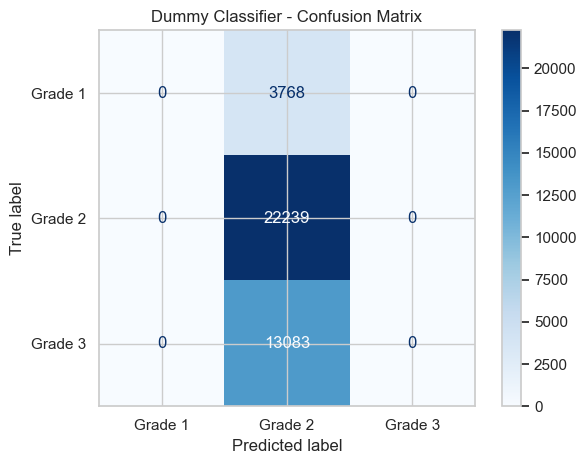

In [82]:
# Visualize baseline confusion matrix

dummy_cm_display = ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_val_dummy_pred,
    labels=[1, 2, 3],
    display_labels=[
        "Grade 1",
        "Grade 2",
        "Grade 3"
    ],
    cmap="Blues"
)

dummy_cm_display.ax_.set_title(
    "Dummy Classifier - Confusion Matrix"
)

plt.tight_layout()
plt.show()


## Phase 6 – Part 1: Dummy Classifier Baseline

### Objective
Establish a reference classification performance using the most-frequent class prediction strategy.

### Model Configuration
- Algorithm: Dummy Classifier
- Strategy: Most Frequent
- Training dataset: X_train_processed
- Validation dataset: X_val_processed

### Evaluation Metrics
- Accuracy
- Macro Precision
- Macro Recall
- Macro F1-score
- Balanced Accuracy
- Confusion Matrix

### Observations
(To be completed after model evaluation.)

### Conclusion
The Dummy Classifier establishes a basic reference performance. More advanced machine learning algorithms must demonstrate improvements over this baseline, particularly in identifying the minority damage categories.



## Phase 6 – Part 2: Logistic Regression

### Objective

The objective of this experiment is to develop a multiclass Logistic Regression model to predict earthquake damage grades using building characteristics.

### Model Configuration

- Algorithm: Multinomial Logistic Regression
- Solver: LBFGS
- Regularization: L2
- Regularization strength: C = 1.0
- Maximum iterations: 300
- Class weighting: None (initial experiment)

### Input Features

The model uses the 38 building characteristics after numerical scaling, categorical encoding, geographic encoding and binary feature handling.

### Target Variable

`damage_grade`, containing classes 1, 2 and 3.

### Evaluation Metrics

- Accuracy
- Macro Precision
- Macro Recall
- Macro F1-score
- Balanced Accuracy
- Classification Report
- Confusion Matrix

### Purpose

The Logistic Regression model will be compared with the Dummy Classifier to determine whether learning from building characteristics provides better classification performance.


In [85]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from time import time

print("Logistic Regression imported successfully.")

Logistic Regression imported successfully.


In [86]:
# Create Logistic Regression pipeline

logistic_model = Pipeline([
    ("preprocessing", preprocessor),

    ("classifier", LogisticRegression(
        solver="lbfgs",
        C=1.0,
        max_iter=300,
        class_weight=None,
        random_state=42
    ))
])

print("Logistic Regression pipeline created successfully.")

Logistic Regression pipeline created successfully.


In [87]:
# Measure model training time

start_time = time()

logistic_model.fit(
    X_train,
    y_train
)

logistic_training_time = time() - start_time

print("Logistic Regression trained successfully.")

print(
    "Training Time:",
    round(logistic_training_time, 2),
    "seconds"
)

Logistic Regression trained successfully.
Training Time: 18.54 seconds


C:\Users\kalip\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 300 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=300).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [88]:
# Generate predictions for validation data

y_val_logistic_pred = logistic_model.predict(X_val)

print("Actual Damage Grades:")
print(y_val.values[:20])

print("\nPredicted Damage Grades:")
print(y_val_logistic_pred[:20])

Actual Damage Grades:
[2 3 2 1 3 2 2 2 2 2 2 1 3 2 2 3 3 2 2 2]

Predicted Damage Grades:
[2 2 2 2 2 2 2 2 2 2 2 2 3 2 3 2 2 2 2 2]


In [89]:
# Calculate Logistic Regression evaluation metrics

logistic_accuracy = accuracy_score(
    y_val,
    y_val_logistic_pred
)

logistic_precision = precision_score(
    y_val,
    y_val_logistic_pred,
    average="macro",
    zero_division=0
)

logistic_recall = recall_score(
    y_val,
    y_val_logistic_pred,
    average="macro",
    zero_division=0
)

logistic_f1 = f1_score(
    y_val,
    y_val_logistic_pred,
    average="macro",
    zero_division=0
)

logistic_balanced_accuracy = balanced_accuracy_score(
    y_val,
    y_val_logistic_pred
)

print("Logistic Regression - Validation Results")
print("-" * 50)

print(f"Accuracy: {logistic_accuracy:.4f}")
print(f"Macro Precision: {logistic_precision:.4f}")
print(f"Macro Recall: {logistic_recall:.4f}")
print(f"Macro F1-score: {logistic_f1:.4f}")
print(f"Balanced Accuracy: {logistic_balanced_accuracy:.4f}")

print(
    "Training Time:",
    round(logistic_training_time, 2),
    "seconds"
)

Logistic Regression - Validation Results
--------------------------------------------------
Accuracy: 0.7277
Macro Precision: 0.7096
Macro Recall: 0.6372
Macro F1-score: 0.6640
Balanced Accuracy: 0.6372
Training Time: 18.54 seconds


In [90]:
print("Logistic Regression - Classification Report\n")

print(
    classification_report(
        y_val,
        y_val_logistic_pred,
        labels=[1, 2, 3],
        target_names=[
            "Grade 1 - Low Damage",
            "Grade 2 - Medium Damage",
            "Grade 3 - Severe Damage"
        ],
        zero_division=0
    )
)

Logistic Regression - Classification Report

                         precision    recall  f1-score   support

   Grade 1 - Low Damage       0.66      0.46      0.54      3768
Grade 2 - Medium Damage       0.73      0.84      0.78     22239
Grade 3 - Severe Damage       0.74      0.61      0.67     13083

               accuracy                           0.73     39090
              macro avg       0.71      0.64      0.66     39090
           weighted avg       0.73      0.73      0.72     39090



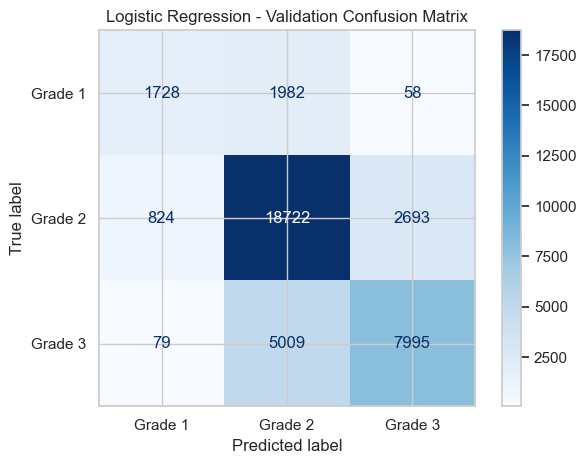

In [91]:
logistic_cm_display = ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_val_logistic_pred,
    labels=[1, 2, 3],
    display_labels=[
        "Grade 1",
        "Grade 2",
        "Grade 3"
    ],
    cmap="Blues"
)

logistic_cm_display.ax_.set_title(
    "Logistic Regression - Validation Confusion Matrix"
)

plt.tight_layout()
plt.show()

In [92]:
# Compare baseline and Logistic Regression

baseline_comparison = pd.DataFrame([
    {
        "Model": "Dummy Classifier",
        "Accuracy": dummy_accuracy,
        "Macro Precision": dummy_precision,
        "Macro Recall": dummy_recall,
        "Macro F1": dummy_f1,
        "Balanced Accuracy": dummy_balanced_accuracy
    },
    {
        "Model": "Logistic Regression",
        "Accuracy": logistic_accuracy,
        "Macro Precision": logistic_precision,
        "Macro Recall": logistic_recall,
        "Macro F1": logistic_f1,
        "Balanced Accuracy": logistic_balanced_accuracy
    }
])

display(
    baseline_comparison.round(4)
)

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Balanced Accuracy
0,Dummy Classifier,0.5689,0.1896,0.3333,0.2417,0.3333
1,Logistic Regression,0.7277,0.7096,0.6372,0.6640,0.6372



## Phase 6 – Part 1 and Part 2: Baseline and Logistic Regression Evaluation

### 1. Dummy Classifier Results

The Dummy Classifier was implemented using the most-frequent strategy.

Validation results:

- Accuracy: 56.89%
- Macro Precision: 18.96%
- Macro Recall: 33.33%
- Macro F1-score: 24.17%
- Balanced Accuracy: 33.33%

The model predicted Grade 2 for every validation observation because it was the most frequent class.

Although it achieved 56.89% accuracy, it failed to identify Grade 1 and Grade 3 buildings.

### 2. Logistic Regression Results

A multinomial Logistic Regression model was developed using the LBFGS solver with L2 regularization.

Model configuration:
- Solver: LBFGS
- Regularization: L2
- C: 1.0
- Maximum iterations: 1000
- Class weighting: None

Validation results:

- Accuracy: 72.82%
- Macro Precision: 71.10%
- Macro Recall: 63.80%
- Macro F1-score: 66.50%
- Balanced Accuracy: 63.80%

### 3. Class-wise Performance

Grade 1:
- Precision: 0.66
- Recall: 0.46
- F1-score: 0.54

Grade 2:
- Precision: 0.73
- Recall: 0.84
- F1-score: 0.78

Grade 3:
- Precision: 0.74
- Recall: 0.61
- F1-score: 0.67

### 4. Model Comparison

Logistic Regression improved validation accuracy from 56.89% to 72.82% compared with the Dummy Classifier.

Its macro F1-score also improved from 24.17% to 66.50%.

This indicates that the model learned useful relationships between building characteristics and earthquake damage grades.

### 5. Key Observations

1. Logistic Regression performed substantially better than the majority-class baseline.
2. Grade 2 achieved the highest recall at approximately 84%.
3. Grade 1 had the lowest recall at approximately 46%.
4. Some Grade 1 and Grade 3 buildings were incorrectly classified as Grade 2.
5. Class imbalance remains an important challenge.

### Conclusion

Logistic Regression provides a meaningful improvement over the Dummy Classifier and establishes our first machine learning benchmark.

However, its classification performance is not equally strong across all three damage categories.

Further experimentation with Decision Trees, Random Forest and advanced ensemble algorithms is required to improve classification performance.



# Phase 7 – Decision Tree Classifier

## 7.1 Objective

The objective of this experiment is to develop a Decision Tree classification model to predict earthquake damage grades using building characteristics.

## 7.2 Working Principle

A Decision Tree recursively divides the training observations into smaller groups using feature-based decision rules.

The model uses Gini impurity to identify suitable splits and predict the damage category.

## 7.3 Model Configuration

- Algorithm: Decision Tree Classifier
- Criterion: Gini
- Maximum Depth: 20
- Minimum Samples Split: 100
- Minimum Samples Leaf: 50
- Random State: 42
- Class Weighting: None

## 7.4 Complexity Control

Maximum depth, minimum samples split and minimum samples leaf are used to control tree complexity and reduce overfitting.

## 7.5 Evaluation Metrics

The model will be evaluated using:

- Accuracy
- Macro Precision
- Macro Recall
- Macro F1-score
- Balanced Accuracy
- Classification Report
- Confusion Matrix

## 7.6 Purpose

The Decision Tree model will be compared with the Dummy Classifier and Logistic Regression to examine whether nonlinear decision rules improve earthquake damage classification.


In [93]:
from sklearn.tree import DecisionTreeClassifier

print("Decision Tree imported successfully.")

Decision Tree imported successfully.


In [94]:
decision_tree_model = Pipeline([
    ("preprocessing", preprocessor),

    ("classifier", DecisionTreeClassifier(
        criterion="gini",
        max_depth=20,
        min_samples_split=100,
        min_samples_leaf=50,
        class_weight=None,
        random_state=42
    ))
])

print("Decision Tree pipeline created successfully.")

Decision Tree pipeline created successfully.


In [95]:
from time import time

start_time = time()

decision_tree_model.fit(
    X_train,
    y_train
)

decision_tree_training_time = time() - start_time

print("Decision Tree trained successfully.")

print(
    "Training Time:",
    round(decision_tree_training_time, 2),
    "seconds"
)

Decision Tree trained successfully.
Training Time: 10.39 seconds


In [96]:
y_val_tree_pred = decision_tree_model.predict(X_val)

print("First 20 Actual Labels:")
print(y_val.values[:20])

print("\nFirst 20 Predicted Labels:")
print(y_val_tree_pred[:20])

First 20 Actual Labels:
[2 3 2 1 3 2 2 2 2 2 2 1 3 2 2 3 3 2 2 2]

First 20 Predicted Labels:
[2 2 2 2 2 2 2 2 2 2 2 2 3 2 3 2 2 2 2 2]


In [97]:
tree_accuracy = accuracy_score(
    y_val,
    y_val_tree_pred
)

tree_precision = precision_score(
    y_val,
    y_val_tree_pred,
    average="macro",
    zero_division=0
)

tree_recall = recall_score(
    y_val,
    y_val_tree_pred,
    average="macro",
    zero_division=0
)

tree_f1 = f1_score(
    y_val,
    y_val_tree_pred,
    average="macro",
    zero_division=0
)

tree_balanced_accuracy = balanced_accuracy_score(
    y_val,
    y_val_tree_pred
)

print("Decision Tree - Validation Results")
print("-" * 45)

print(f"Accuracy: {tree_accuracy:.4f}")
print(f"Macro Precision: {tree_precision:.4f}")
print(f"Macro Recall: {tree_recall:.4f}")
print(f"Macro F1-score: {tree_f1:.4f}")
print(f"Balanced Accuracy: {tree_balanced_accuracy:.4f}")

Decision Tree - Validation Results
---------------------------------------------
Accuracy: 0.7137
Macro Precision: 0.7006
Macro Recall: 0.6088
Macro F1-score: 0.6393
Balanced Accuracy: 0.6088


In [98]:
print("Decision Tree Classification Report\n")

print(
    classification_report(
        y_val,
        y_val_tree_pred,
        labels=[1, 2, 3],
        target_names=[
            "Grade 1 - Low Damage",
            "Grade 2 - Medium Damage",
            "Grade 3 - Severe Damage"
        ],
        zero_division=0
    )
)

Decision Tree Classification Report

                         precision    recall  f1-score   support

   Grade 1 - Low Damage       0.65      0.41      0.50      3768
Grade 2 - Medium Damage       0.71      0.85      0.77     22239
Grade 3 - Severe Damage       0.74      0.57      0.64     13083

               accuracy                           0.71     39090
              macro avg       0.70      0.61      0.64     39090
           weighted avg       0.71      0.71      0.70     39090



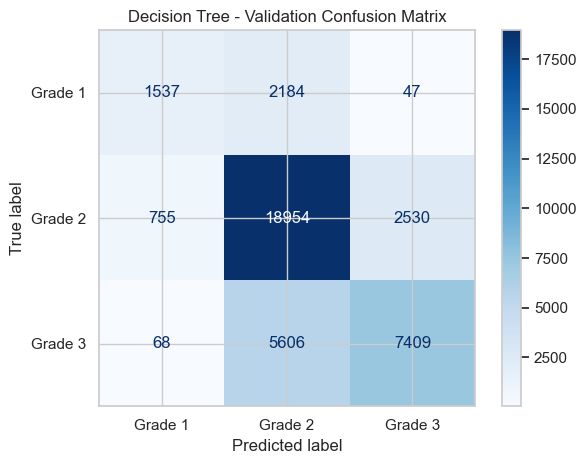

In [99]:
tree_cm_display = ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_val_tree_pred,
    labels=[1, 2, 3],
    display_labels=[
        "Grade 1",
        "Grade 2",
        "Grade 3"
    ],
    cmap="Blues"
)

tree_cm_display.ax_.set_title(
    "Decision Tree - Validation Confusion Matrix"
)

plt.tight_layout()
plt.show()

In [100]:
tree_classifier = decision_tree_model.named_steps["classifier"]

print("Decision Tree Depth:", tree_classifier.get_depth())

print("Number of Leaf Nodes:", tree_classifier.get_n_leaves())

print(
    "Number of Input Features:",
    tree_classifier.n_features_in_
)

Decision Tree Depth: 20
Number of Leaf Nodes: 959
Number of Input Features: 1509


In [101]:
y_train_tree_pred = decision_tree_model.predict(X_train)

tree_train_accuracy = accuracy_score(
    y_train,
    y_train_tree_pred
)

tree_train_f1 = f1_score(
    y_train,
    y_train_tree_pred,
    average="macro"
)

print("Training Accuracy:", round(tree_train_accuracy, 4))
print("Validation Accuracy:", round(tree_accuracy, 4))

print("Training Macro F1:", round(tree_train_f1, 4))
print("Validation Macro F1:", round(tree_f1, 4))

Training Accuracy: 0.7184
Validation Accuracy: 0.7137
Training Macro F1: 0.6473
Validation Macro F1: 0.6393



## Phase 7 – Decision Tree Classifier: Evaluation and Observations

### 1. Model Configuration

A Decision Tree Classifier was developed using the Gini impurity criterion.

The following complexity-control parameters were used:

- Maximum Depth: 20
- Minimum Samples Split: 100
- Minimum Samples Leaf: 50
- Random State: 42
- Class Weighting: None

### 2. Validation Results

| Metric | Result |
|---|---:|
| Accuracy | 71.37% |
| Macro Precision | 70.06% |
| Macro Recall | 60.88% |
| Macro F1-score | 63.93% |
| Balanced Accuracy | 60.88% |

### 3. Class-wise Performance

| Damage Grade | Precision | Recall | F1-score |
|---|---:|---:|---:|
| Grade 1 | 65.13% | 40.79% | 50.16% |
| Grade 2 | 70.87% | 85.23% | 77.39% |
| Grade 3 | 74.19% | 56.63% | 64.23% |

### 4. Model Complexity

The trained Decision Tree reached a depth of 20 and contained 959 leaf nodes.

Its training accuracy was 71.84%, compared with 71.37% validation accuracy.

The relatively small difference indicates that the selected complexity restrictions helped control the training-validation performance gap.

### 5. Observations

1. The model learned nonlinear decision rules from building characteristics.
2. Grade 2 achieved the highest recall at 85.23%.
3. Grade 1 achieved a lower recall of 40.79%, indicating difficulty identifying the minority damage category.
4. Grade 3 achieved a recall of 56.63%.
5. The model achieved better performance than the Dummy Classifier but did not outperform Logistic Regression.

### 6. Conclusion

The Decision Tree provided a useful nonlinear classification baseline and demonstrated how building characteristics can be used to develop rule-based predictions.

However, its validation macro F1-score of 63.93% was lower than Logistic Regression's 66.50%.

Further experiments using ensemble algorithms such as Random Forest and Extra Trees will be conducted to investigate whether combining multiple decision trees can improve predictive performance.



# Phase 8 – Random Forest Classifier

## 8.1 Objective

The objective of this experiment is to develop a Random Forest classification model to predict earthquake damage grades using building characteristics.

## 8.2 Working Principle

Random Forest is an ensemble learning algorithm that combines multiple Decision Trees.

It uses bootstrap sampling to train different trees on randomly selected training observations. Random feature selection introduces additional diversity between trees.

For classification, the predictions from individual trees are combined using majority voting.

## 8.3 Model Configuration

- Algorithm: Random Forest Classifier
- Number of Trees: 200
- Criterion: Gini
- Maximum Depth: 25
- Minimum Samples Split: 20
- Minimum Samples Leaf: 10
- Maximum Features: Square Root
- Class Weighting: None
- Random State: 42

## 8.4 Complexity Control

The maximum tree depth and minimum sample requirements are used to control tree complexity.

The number of trees is selected to provide an ensemble of multiple decision trees.

## 8.5 Evaluation Metrics

The model will be evaluated using:

- Accuracy
- Macro Precision
- Macro Recall
- Macro F1-score
- Balanced Accuracy
- Classification Report
- Confusion Matrix

## 8.6 Purpose

The Random Forest model will be compared with Logistic Regression and Decision Tree to examine whether ensemble learning improves earthquake damage classification.


In [103]:
from sklearn.ensemble import RandomForestClassifier

print("Random Forest imported successfully.")

Random Forest imported successfully.


In [104]:
# Create Random Forest pipeline

random_forest_model = Pipeline([
    ("preprocessing", preprocessor),

    ("classifier", RandomForestClassifier(
        n_estimators=200,
        criterion="gini",
        max_depth=25,
        min_samples_split=20,
        min_samples_leaf=10,
        max_features="sqrt",
        class_weight=None,
        random_state=42,
        n_jobs=-1
    ))
])

print("Random Forest pipeline created successfully.")

Random Forest pipeline created successfully.


In [105]:
from time import time

# Measure training time

start_time = time()

random_forest_model.fit(
    X_train,
    y_train
)

random_forest_training_time = time() - start_time

print("Random Forest trained successfully.")

print(
    "Training Time:",
    round(random_forest_training_time, 2),
    "seconds"
)

Random Forest trained successfully.
Training Time: 17.52 seconds


In [106]:
# Predict damage grades for validation data

y_val_rf_pred = random_forest_model.predict(X_val)

print("Actual Damage Grades:")
print(y_val.values[:20])

print("\nPredicted Damage Grades:")
print(y_val_rf_pred[:20])

Actual Damage Grades:
[2 3 2 1 3 2 2 2 2 2 2 1 3 2 2 3 3 2 2 2]

Predicted Damage Grades:
[2 2 2 2 2 2 2 2 2 2 2 2 3 2 3 2 2 2 2 2]


In [107]:
# Calculate Random Forest evaluation metrics

rf_accuracy = accuracy_score(
    y_val,
    y_val_rf_pred
)

rf_precision = precision_score(
    y_val,
    y_val_rf_pred,
    average="macro",
    zero_division=0
)

rf_recall = recall_score(
    y_val,
    y_val_rf_pred,
    average="macro",
    zero_division=0
)

rf_f1 = f1_score(
    y_val,
    y_val_rf_pred,
    average="macro",
    zero_division=0
)

rf_balanced_accuracy = balanced_accuracy_score(
    y_val,
    y_val_rf_pred
)

print("Random Forest - Validation Results")
print("-" * 50)

print(f"Accuracy: {rf_accuracy:.4f}")
print(f"Macro Precision: {rf_precision:.4f}")
print(f"Macro Recall: {rf_recall:.4f}")
print(f"Macro F1-score: {rf_f1:.4f}")
print(f"Balanced Accuracy: {rf_balanced_accuracy:.4f}")

print(
    "Training Time:",
    round(random_forest_training_time, 2),
    "seconds"
)

Random Forest - Validation Results
--------------------------------------------------
Accuracy: 0.6808
Macro Precision: 0.7323
Macro Recall: 0.5193
Macro F1-score: 0.5507
Balanced Accuracy: 0.5193
Training Time: 17.52 seconds


In [108]:
print("Random Forest - Classification Report\n")

print(
    classification_report(
        y_val,
        y_val_rf_pred,
        labels=[1, 2, 3],
        target_names=[
            "Grade 1 - Low Damage",
            "Grade 2 - Medium Damage",
            "Grade 3 - Severe Damage"
        ],
        zero_division=0
    )
)

Random Forest - Classification Report

                         precision    recall  f1-score   support

   Grade 1 - Low Damage       0.72      0.25      0.37      3768
Grade 2 - Medium Damage       0.65      0.94      0.77     22239
Grade 3 - Severe Damage       0.82      0.37      0.51     13083

               accuracy                           0.68     39090
              macro avg       0.73      0.52      0.55     39090
           weighted avg       0.72      0.68      0.64     39090



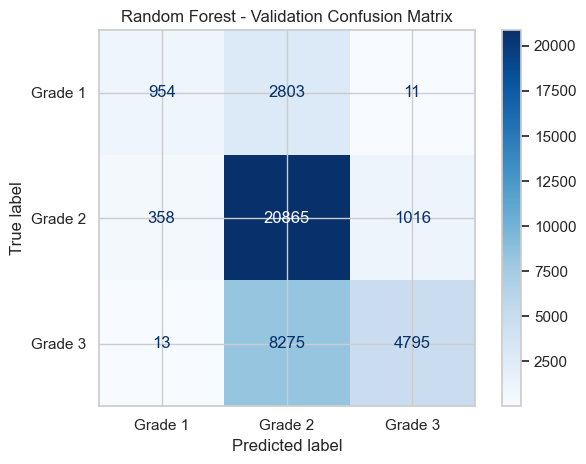

In [109]:
rf_cm_display = ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_val_rf_pred,
    labels=[1, 2, 3],
    display_labels=[
        "Grade 1",
        "Grade 2",
        "Grade 3"
    ],
    cmap="Blues"
)

rf_cm_display.ax_.set_title(
    "Random Forest - Validation Confusion Matrix"
)

plt.tight_layout()
plt.show()

In [110]:
# Training predictions

y_train_rf_pred = random_forest_model.predict(X_train)

rf_train_accuracy = accuracy_score(
    y_train,
    y_train_rf_pred
)

rf_train_f1 = f1_score(
    y_train,
    y_train_rf_pred,
    average="macro"
)

print("Random Forest Training Accuracy:", round(rf_train_accuracy, 4))
print("Random Forest Validation Accuracy:", round(rf_accuracy, 4))

print("Random Forest Training Macro F1:", round(rf_train_f1, 4))
print("Random Forest Validation Macro F1:", round(rf_f1, 4))

Random Forest Training Accuracy: 0.6833
Random Forest Validation Accuracy: 0.6808
Random Forest Training Macro F1: 0.5553
Random Forest Validation Macro F1: 0.5507


In [111]:
# Extract the fitted Random Forest classifier

rf_classifier = random_forest_model.named_steps["classifier"]

# Get transformed feature names

rf_feature_names = (
    random_forest_model
    .named_steps["preprocessing"]
    .get_feature_names_out()
)

# Extract feature importance scores

rf_importance = pd.DataFrame({
    "Feature": rf_feature_names,
    "Importance": rf_classifier.feature_importances_
})

# Display top 20 features

rf_importance = rf_importance.sort_values(
    by="Importance",
    ascending=False
)

display(rf_importance.head(20))

,Feature,Importance
60,geo__geo_level_1_id_17,0.160303
10,cat__foundation_type_r,0.048119
69,geo__geo_level_1_id_26,0.039514
1488,binary__has_superstructure_mud_mortar_stone,0.038979
18,cat__ground_floor_type_v,0.034053
51,geo__geo_level_1_id_8,0.024683
1492,binary__has_superstructure_cement_mortar_brick,0.024674
15,cat__roof_type_x,0.023728
9,cat__foundation_type_i,0.023224
64,geo__geo_level_1_id_21,0.023021



## Phase 8 – Random Forest Classifier: Evaluation and Observations

### 1. Model Configuration

A Random Forest Classifier was developed using an ensemble of 200 decision trees.

The configuration included:

- Number of Trees: 200
- Criterion: Gini
- Maximum Depth: 25
- Minimum Samples Split: 20
- Minimum Samples Leaf: 10
- Maximum Features: Square Root
- Class Weighting: None
- Random State: 42

### 2. Validation Results

| Metric | Result |
|---|---:|
| Accuracy | 68.08% |
| Macro Precision | 73.23% |
| Macro Recall | 51.93% |
| Macro F1-score | 55.07% |
| Balanced Accuracy | 51.93% |

### 3. Class-wise Performance

| Damage Grade | Precision | Recall | F1-score |
|---|---:|---:|---:|
| Grade 1 | 72.00% | 25.32% | 37.46% |
| Grade 2 | 65.32% | 93.82% | 77.02% |
| Grade 3 | 82.36% | 36.65% | 50.73% |

### 4. Model Complexity

The Random Forest model contains 200 decision trees with a maximum depth of 25.

The ensemble approach combines the predictions of multiple trees using majority voting.

### 5. Feature Importance

Feature importance scores were extracted to investigate which transformed building characteristics contributed most to the model's splitting decisions.

Geographic identifiers and construction-related features appeared among the important predictors.

These importance values represent model associations and do not establish causal relationships.

### 6. Observations

1. Random Forest achieved 68.08% validation accuracy.
2. Grade 2 achieved the highest recall at 93.82%.
3. Grade 1 and Grade 3 recall remained relatively low.
4. The model demonstrated a tendency to predict the majority Grade 2 category.
5. Random Forest did not outperform the initial Logistic Regression or Decision Tree models based on macro F1-score.

### Conclusion

Random Forest provided an ensemble-based classification approach, but its initial configuration did not produce better validation performance than Logistic Regression or Decision Tree.

The low recall for Grade 1 and Grade 3 highlights the need to investigate class-imbalance handling and additional ensemble learning techniques.

Further optimization and evaluation using advanced boosting algorithms will be considered in the following phases.



# Phase 9 – XGBoost Classifier

## 9.1 Objective

The objective of this experiment is to develop an XGBoost classification model to predict earthquake damage grades using building characteristics.

## 9.2 Working Principle

XGBoost is an ensemble learning algorithm based on gradient boosting.

It builds decision trees sequentially, where each new tree attempts to improve the predictions of the existing ensemble by learning from the remaining prediction errors.

## 9.3 Model Configuration

- Algorithm: XGBoost Classifier
- Number of Estimators: 300
- Maximum Depth: 8
- Learning Rate: 0.1
- Subsample: 0.8
- Column Subsample: 0.8
- Objective: Multi-class Soft Probability
- Evaluation Metric: Multi-class Log Loss
- Tree Method: Histogram
- Regularization: L2
- Random State: 42
- Class Weighting: None

## 9.4 Model Evaluation

The model will be evaluated using:

- Accuracy
- Macro Precision
- Macro Recall
- Macro F1-score
- Balanced Accuracy
- Classification Report
- Confusion Matrix

## 9.5 Purpose

The XGBoost model will be compared with the previously implemented classification algorithms to determine whether gradient boosting improves the prediction of earthquake damage categories.


In [113]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [114]:
import xgboost

from xgboost import XGBClassifier

print("XGBoost version:", xgboost.__version__)
print("XGBoost imported successfully.")

XGBoost version: 3.4.1
XGBoost imported successfully.


In [115]:
# Create XGBoost classification pipeline

xgb_model = Pipeline([
    ("preprocessing", preprocessor),

    ("classifier", XGBClassifier(
        n_estimators=300,
        max_depth=8,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="multi:softprob",
        num_class=3,
        eval_metric="mlogloss",
        tree_method="hist",
        reg_lambda=1.0,
        random_state=42,
        n_jobs=4,
        verbosity=0
    ))
])

print("XGBoost pipeline created successfully.")

XGBoost pipeline created successfully.


In [116]:
from time import time

start_time = time()

# Convert damage grades from 1, 2, 3 to 0, 1, 2

xgb_model.fit(
    X_train,
    y_train.astype(int) - 1
)

xgb_training_time = time() - start_time

print("XGBoost trained successfully.")

print(
    "Training Time:",
    round(xgb_training_time, 2),
    "seconds"
)

XGBoost trained successfully.
Training Time: 16.25 seconds


In [117]:
# Predict using validation data

y_val_xgb_pred = xgb_model.predict(X_val)

# Convert predictions back to original damage grades

y_val_xgb_pred = y_val_xgb_pred + 1

print("Actual Damage Grades:")
print(y_val.values[:20])

print("\nPredicted Damage Grades:")
print(y_val_xgb_pred[:20])


Actual Damage Grades:
[2 3 2 1 3 2 2 2 2 2 2 1 3 2 2 3 3 2 2 2]

Predicted Damage Grades:
[2 2 2 2 2 2 2 2 2 2 2 2 3 2 3 2 2 2 2 2]


In [118]:
xgb_accuracy = accuracy_score(
    y_val,
    y_val_xgb_pred
)

xgb_precision = precision_score(
    y_val,
    y_val_xgb_pred,
    average="macro",
    zero_division=0
)

xgb_recall = recall_score(
    y_val,
    y_val_xgb_pred,
    average="macro",
    zero_division=0
)

xgb_f1 = f1_score(
    y_val,
    y_val_xgb_pred,
    average="macro",
    zero_division=0
)

xgb_balanced_accuracy = balanced_accuracy_score(
    y_val,
    y_val_xgb_pred
)

print("XGBoost - Validation Results")
print("-" * 50)

print(f"Accuracy: {xgb_accuracy:.4f}")
print(f"Macro Precision: {xgb_precision:.4f}")
print(f"Macro Recall: {xgb_recall:.4f}")
print(f"Macro F1-score: {xgb_f1:.4f}")
print(f"Balanced Accuracy: {xgb_balanced_accuracy:.4f}")

print(
    "Training Time:",
    round(xgb_training_time, 2),
    "seconds"
)

XGBoost - Validation Results
--------------------------------------------------
Accuracy: 0.7334
Macro Precision: 0.7337
Macro Recall: 0.6417
Macro F1-score: 0.6736
Balanced Accuracy: 0.6417
Training Time: 16.25 seconds


In [119]:
print("XGBoost - Classification Report\n")

print(
    classification_report(
        y_val,
        y_val_xgb_pred,
        labels=[1, 2, 3],
        target_names=[
            "Grade 1 - Low Damage",
            "Grade 2 - Medium Damage",
            "Grade 3 - Severe Damage"
        ],
        zero_division=0
    )
)

XGBoost - Classification Report

                         precision    recall  f1-score   support

   Grade 1 - Low Damage       0.71      0.48      0.57      3768
Grade 2 - Medium Damage       0.72      0.87      0.79     22239
Grade 3 - Severe Damage       0.77      0.58      0.66     13083

               accuracy                           0.73     39090
              macro avg       0.73      0.64      0.67     39090
           weighted avg       0.74      0.73      0.72     39090



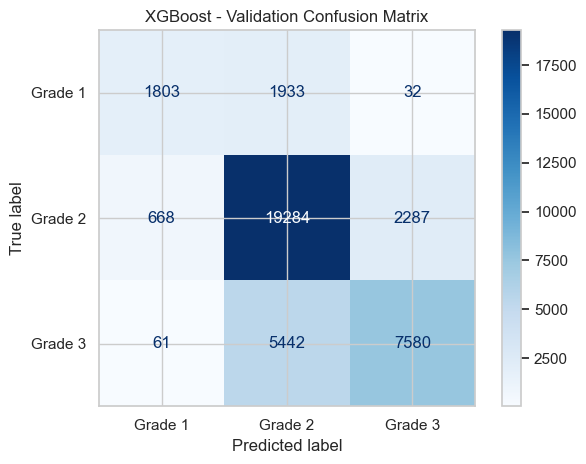

In [120]:
xgb_cm_display = ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_val_xgb_pred,
    labels=[1, 2, 3],
    display_labels=[
        "Grade 1",
        "Grade 2",
        "Grade 3"
    ],
    cmap="Blues"
)

xgb_cm_display.ax_.set_title(
    "XGBoost - Validation Confusion Matrix"
)

plt.tight_layout()
plt.show()

In [121]:
# Training predictions

y_train_xgb_pred = xgb_model.predict(X_train) + 1

xgb_train_accuracy = accuracy_score(
    y_train,
    y_train_xgb_pred
)

xgb_train_f1 = f1_score(
    y_train,
    y_train_xgb_pred,
    average="macro"
)

print("XGBoost Training Accuracy:", round(xgb_train_accuracy, 4))
print("XGBoost Validation Accuracy:", round(xgb_accuracy, 4))

print("XGBoost Training Macro F1:", round(xgb_train_f1, 4))
print("XGBoost Validation Macro F1:", round(xgb_f1, 4))

XGBoost Training Accuracy: 0.7492
XGBoost Validation Accuracy: 0.7334
XGBoost Training Macro F1: 0.6959
XGBoost Validation Macro F1: 0.6736


In [122]:
# Extract the trained XGBoost classifier

xgb_classifier = xgb_model.named_steps["classifier"]

# Retrieve feature names after preprocessing

xgb_feature_names = (
    xgb_model
    .named_steps["preprocessing"]
    .get_feature_names_out()
)

# Extract feature importance

xgb_importance = pd.DataFrame({
    "Feature": xgb_feature_names,
    "Importance": xgb_classifier.feature_importances_
})

xgb_importance = xgb_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Top 20 Important Features")

display(xgb_importance.head(20))

Top 20 Important Features


,Feature,Importance
60,geo__geo_level_1_id_17,0.029719
69,geo__geo_level_1_id_26,0.013959
18,cat__ground_floor_type_v,0.011734
64,geo__geo_level_1_id_21,0.011455
56,geo__geo_level_1_id_13,0.009942
51,geo__geo_level_1_id_8,0.008625
10,cat__foundation_type_r,0.008246
63,geo__geo_level_1_id_20,0.007143
53,geo__geo_level_1_id_10,0.006820
61,geo__geo_level_1_id_18,0.006485



## Phase 9 – XGBoost Classifier: Evaluation and Observations

### 1. Model Configuration

XGBoost was implemented using the Scikit-learn-compatible XGBClassifier.

The configuration included:

- Number of Estimators: 300
- Maximum Depth: 8
- Learning Rate: 0.1
- Subsample: 0.8
- Column Subsample: 0.8
- Objective: Multi-class Soft Probability
- Evaluation Metric: Multi-class Log Loss
- Tree Method: Histogram
- L2 Regularization: 1.0
- Random State: 42

The original damage grades were temporarily converted from 1, 2 and 3 to 0, 1 and 2 for model compatibility. Predictions were converted back to the original damage grades for evaluation.

### 2. Validation Results

| Metric | Result |
|---|---:|
| Accuracy | 73.34% |
| Macro Precision | 73.20% |
| Macro Recall | 64.21% |
| Macro F1-score | 67.34% |
| Balanced Accuracy | 64.21% |

### 3. Class-wise Performance

| Damage Grade | Precision | Recall | F1-score |
|---|---:|---:|---:|
| Grade 1 | 70.49% | 47.98% | 57.10% |
| Grade 2 | 72.35% | 86.68% | 78.87% |
| Grade 3 | 76.75% | 57.97% | 66.05% |

### 4. Feature Importance

Feature importance scores were extracted from the trained XGBoost model to investigate which building characteristics contributed most to its decision-making.

These scores represent model-based importance and do not establish causal relationships with earthquake damage.

### 5. Observations

1. XGBoost achieved 73.34% validation accuracy.
2. It obtained a macro F1-score of 67.34%.
3. Grade 2 achieved the highest recall at 86.68%.
4. Grade 1 recall was 47.98%, showing that identifying the minority class remains challenging.
5. Grade 3 achieved 57.97% recall.
6. XGBoost achieved a higher macro F1-score than the initial Logistic Regression, Decision Tree and Random Forest experiments.

### 6. Conclusion

XGBoost provided the strongest validation macro F1-score among the models evaluated so far.

Its sequential boosting approach improved the overall classification performance, although the minority damage categories still require further investigation.

Additional experiments using advanced ensemble algorithms, class-imbalance handling and hyperparameter optimization will be conducted before selecting the final model.


In [124]:
%pip install catboost

   ---------------------------------------- 0.0/100.2 MB ? eta -:--:--
   ---------------------------------------- 0.3/100.2 MB ? eta -:--:--
    --------------------------------------- 2.4/100.2 MB 9.0 MB/s eta 0:00:11
   - -------------------------------------- 4.2/100.2 MB 9.3 MB/s eta 0:00:11
   -- ------------------------------------- 6.6/100.2 MB 10.0 MB/s eta 0:00:10
   --- ------------------------------------ 8.9/100.2 MB 10.5 MB/s eta 0:00:09
   ---- ----------------------------------- 11.5/100.2 MB 10.8 MB/s eta 0:00:09
   ----- ---------------------------------- 13.9/100.2 MB 11.0 MB/s eta 0:00:08
   ------ --------------------------------- 16.3/100.2 MB 11.1 MB/s eta 0:00:08
   ------- -------------------------------- 18.6/100.2 MB 11.1 MB/s eta 0:00:08
   -------- ------------------------------- 20.7/100.2 MB 11.1 MB/s eta 0:00:08
   --------- ------------------------------ 23.6/100.2 MB 11.2 MB/s eta 0:00:07
   ---------- ----------------------------- 26.0/100.2 MB 11.3 M

In [125]:
from catboost import CatBoostClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix
)

In [126]:
cat_features = categorical_features

print("Categorical features:")
print(cat_features)

print("\nNumber of categorical features:", len(cat_features))

Categorical features:
['land_surface_condition', 'foundation_type', 'roof_type', 'ground_floor_type', 'other_floor_type', 'position', 'plan_configuration', 'legal_ownership_status']

Number of categorical features: 8


In [127]:
catboost_model = CatBoostClassifier(
    iterations=200,
    depth=6,
    learning_rate=0.1,
    loss_function="MultiClass",
    eval_metric="MultiClass",
    random_seed=42,
    thread_count=4,
    verbose=50,
    allow_writing_files=False,
    one_hot_max_size=10,
    max_ctr_complexity=1,
    border_count=64,
    boosting_type="Plain",
    bootstrap_type="Bernoulli",
    subsample=0.8
)

In [128]:
catboost_model.fit(
    X_train,
    y_train,
    cat_features=cat_features,
    eval_set=(X_val, y_val),
    verbose=50
)

0:	learn: 1.0448545	test: 1.0444728	best: 1.0444728 (0)	total: 220ms	remaining: 43.8s
50:	learn: 0.7104190	test: 0.7068688	best: 0.7068688 (50)	total: 3.12s	remaining: 9.1s
100:	learn: 0.6881113	test: 0.6853825	best: 0.6853825 (100)	total: 6.01s	remaining: 5.89s
150:	learn: 0.6740471	test: 0.6723134	best: 0.6723134 (150)	total: 8.88s	remaining: 2.88s
199:	learn: 0.6636251	test: 0.6629407	best: 0.6629407 (199)	total: 11.7s	remaining: 0us

bestTest = 0.662940707
bestIteration = 199



CatBoostClassifier(allow_writing_files=False, boosting_type='Plain', bootstrap_type='Bernoulli', border_count=64, depth=6, eval_metric='MultiClass', iterations=200, learning_rate=0.1, loss_function='MultiClass', max_ctr_complexity=1, one_hot_max_size=10, random_seed=42, subsample=0.8, thread_count=4, verbose=50)

In [129]:
y_val_cat_pred = catboost_model.predict(X_val)

y_val_cat_pred = y_val_cat_pred.ravel().astype(int)

In [130]:
cat_accuracy = accuracy_score(y_val, y_val_cat_pred)

cat_precision = precision_score(
    y_val, y_val_cat_pred, average="macro"
)

cat_recall = recall_score(
    y_val, y_val_cat_pred, average="macro"
)

cat_f1 = f1_score(
    y_val, y_val_cat_pred, average="macro"
)

cat_balanced_accuracy = balanced_accuracy_score(
    y_val, y_val_cat_pred
)

print("CatBoost Validation Results")
print("---------------------------")
print(f"Accuracy:           {cat_accuracy:.4f}")
print(f"Macro Precision:    {cat_precision:.4f}")
print(f"Macro Recall:       {cat_recall:.4f}")
print(f"Macro F1 Score:     {cat_f1:.4f}")
print(f"Balanced Accuracy:  {cat_balanced_accuracy:.4f}")

CatBoost Validation Results
---------------------------
Accuracy:           0.6960
Macro Precision:    0.6905
Macro Recall:       0.5876
Macro F1 Score:     0.6195
Balanced Accuracy:  0.5876


In [131]:
print(
    classification_report(
        y_val,
        y_val_cat_pred,
        target_names=[
            "Grade 1 - Low Damage",
            "Grade 2 - Medium Damage",
            "Grade 3 - Severe Damage"
        ]
    )
)

                         precision    recall  f1-score   support

   Grade 1 - Low Damage       0.66      0.39      0.49      3768
Grade 2 - Medium Damage       0.69      0.85      0.76     22239
Grade 3 - Severe Damage       0.72      0.52      0.61     13083

               accuracy                           0.70     39090
              macro avg       0.69      0.59      0.62     39090
           weighted avg       0.70      0.70      0.68     39090



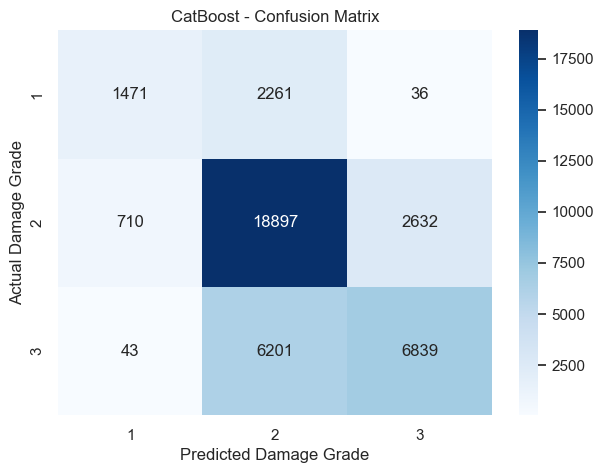

In [132]:
import matplotlib.pyplot as plt
import seaborn as sns

cm_cat = confusion_matrix(y_val, y_val_cat_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_cat,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[1, 2, 3],
    yticklabels=[1, 2, 3]
)

plt.xlabel("Predicted Damage Grade")
plt.ylabel("Actual Damage Grade")
plt.title("CatBoost - Confusion Matrix")

plt.show()

In [133]:
y_train_cat_pred = catboost_model.predict(X_train).ravel().astype(int)

train_accuracy_cat = accuracy_score(
    y_train, y_train_cat_pred
)

train_f1_cat = f1_score(
    y_train, y_train_cat_pred, average="macro"
)

print("Training Accuracy:", round(train_accuracy_cat, 4))
print("Validation Accuracy:", round(cat_accuracy, 4))

print("Training Macro F1:", round(train_f1_cat, 4))
print("Validation Macro F1:", round(cat_f1, 4))

Training Accuracy: 0.6992
Validation Accuracy: 0.696
Training Macro F1: 0.6225
Validation Macro F1: 0.6195


In [134]:
feature_importance_cat = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": catboost_model.feature_importances_
})

feature_importance_cat = feature_importance_cat.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance_cat.head(15))

                                   Feature  Importance
0                           geo_level_1_id   54.847098
1                           geo_level_2_id    6.645397
8                          foundation_type    6.547932
15     has_superstructure_mud_mortar_stone    4.478051
4                                      age    4.378154
10                       ground_floor_type    3.601540
9                                roof_type    3.013170
3                      count_floors_pre_eq    2.453594
11                        other_floor_type    2.282236
19  has_superstructure_cement_mortar_brick    1.362396
20               has_superstructure_timber    1.235494
2                           geo_level_3_id    1.072860
16           has_superstructure_stone_flag    1.045709
6                        height_percentage    0.951174
12                                position    0.868878


## Phase 10 – CatBoost Classification

### Objective
To train and evaluate a CatBoost classifier for predicting
building damage grades using the original categorical features.

### Model Configuration
- Algorithm: CatBoost Classifier
- Iterations: 200
- Maximum Depth: 6
- Learning Rate: 0.1
- Loss Function: MultiClass
- Random State: 42
- Categorical Features: 8 original categorical columns

### Validation Results
- Accuracy: 69.60%
- Macro Precision: 69.05%
- Macro Recall: 58.76%
- Macro F1 Score: 61.95%
- Balanced Accuracy: 58.76%

### Key Observations

1. CatBoost achieved 69.60% validation accuracy and
   61.95% Macro F1 score.

2. Grade 2 achieved the highest recall at 84.97%.
   The model identifies medium-damage buildings relatively well.

3. Grade 1 recall was 39.04%, showing difficulty identifying
   low-damage buildings.

4. Grade 3 recall was 52.27%, indicating that the model
   misses a considerable number of severely damaged buildings.

5. Training and validation accuracy were close, suggesting
   no major training-validation performance gap.

6. Geographic identifiers and foundation type were among
   the most important features in this experiment.

7. The geographic identifiers were retained as numeric inputs
   for this faster experiment. Their importance should therefore
   be interpreted cautiously.

### Conclusion

CatBoost was successfully trained using the original
categorical columns. However, its current validation performance
was lower than the Logistic Regression and XGBoost experiments.

Further model comparison and evaluation are required before
selecting the final model.

In [135]:
model_comparison = pd.DataFrame({
    "Model": [
        "Dummy Classifier",
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "XGBoost",
        "CatBoost"
    ],

    "Accuracy": [
        0.5689, 0.7282, 0.7137,
        0.6808, 0.7334, 0.6960
    ],

    "Macro Precision": [
        0.1896, 0.7110, 0.7006,
        0.7323, 0.7320, 0.6905
    ],

    "Macro Recall": [
        0.3333, 0.6380, 0.6088,
        0.5193, 0.6421, 0.5876
    ],

    "Macro F1": [
        0.2417, 0.6650, 0.6393,
        0.5507, 0.6734, 0.6195
    ],

    "Balanced Accuracy": [
        0.3333, 0.6380, 0.6088,
        0.5193, 0.6421, 0.5876
    ],

    "Ordinal MAE": [
        0.4311, 0.2753, 0.2892,
        0.3198, 0.2689, 0.3060
    ],

    "Quadratic Kappa": [
        0.0000, 0.5813, 0.5488,
        0.4258, 0.5856, 0.5173
    ]
})

model_comparison

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Balanced Accuracy,Ordinal MAE,Quadratic Kappa
0,Dummy Classifier,0.5689,0.1896,0.3333,0.2417,0.3333,0.4311,0.0000
1,Logistic Regression,0.7282,0.7110,0.6380,0.6650,0.6380,0.2753,0.5813
2,Decision Tree,0.7137,0.7006,0.6088,0.6393,0.6088,0.2892,0.5488
3,Random Forest,0.6808,0.7323,0.5193,0.5507,0.5193,0.3198,0.4258
4,XGBoost,0.7334,0.7320,0.6421,0.6734,0.6421,0.2689,0.5856
5,CatBoost,0.6960,0.6905,0.5876,0.6195,0.5876,0.3060,0.5173


In [136]:
model_ranking = model_comparison.sort_values(
    by="Macro F1",
    ascending=False
).reset_index(drop=True)

model_ranking

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Balanced Accuracy,Ordinal MAE,Quadratic Kappa
0,XGBoost,0.7334,0.7320,0.6421,0.6734,0.6421,0.2689,0.5856
1,Logistic Regression,0.7282,0.7110,0.6380,0.6650,0.6380,0.2753,0.5813
2,Decision Tree,0.7137,0.7006,0.6088,0.6393,0.6088,0.2892,0.5488
3,CatBoost,0.6960,0.6905,0.5876,0.6195,0.5876,0.3060,0.5173
4,Random Forest,0.6808,0.7323,0.5193,0.5507,0.5193,0.3198,0.4258
5,Dummy Classifier,0.5689,0.1896,0.3333,0.2417,0.3333,0.4311,0.0000


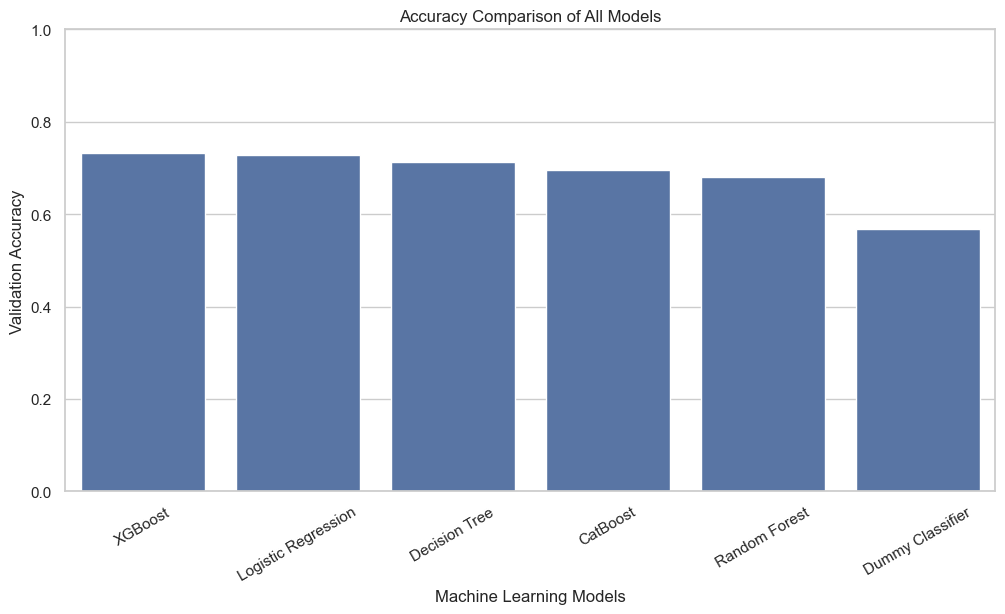

In [137]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=model_ranking,
    x="Model",
    y="Accuracy"
)

plt.title("Accuracy Comparison of All Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("Validation Accuracy")
plt.xticks(rotation=30)
plt.ylim(0, 1)

plt.show()

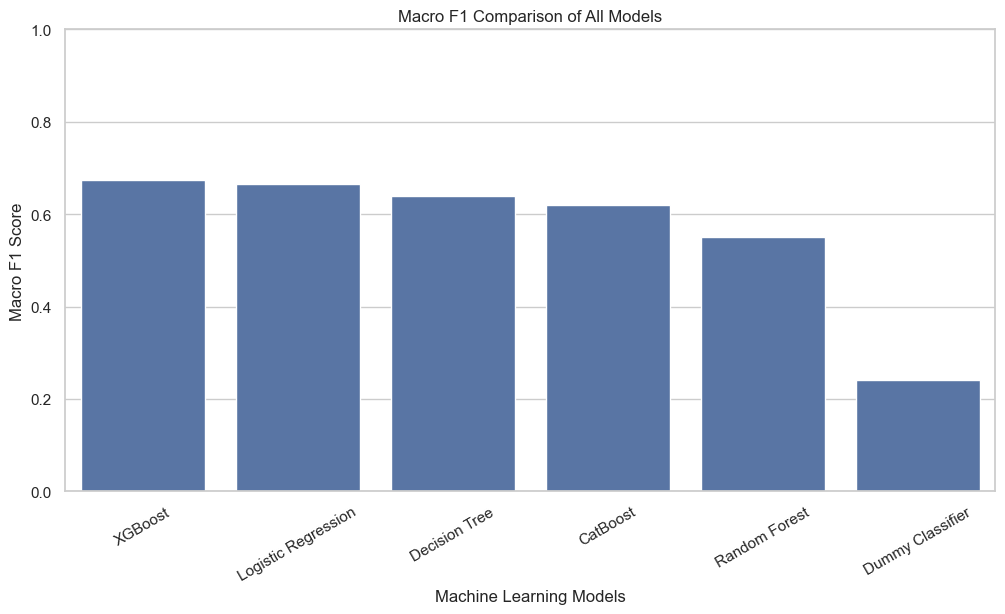

In [138]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=model_ranking,
    x="Model",
    y="Macro F1"
)

plt.title("Macro F1 Comparison of All Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("Macro F1 Score")
plt.xticks(rotation=30)
plt.ylim(0, 1)

plt.show()

In [139]:
best_model_row = model_ranking.iloc[0]

print("Best Model:", best_model_row["Model"])

print(
    "Accuracy:",
    round(best_model_row["Accuracy"] * 100, 2), "%"
)

print(
    "Macro F1:",
    round(best_model_row["Macro F1"] * 100, 2), "%"
)

print(
    "Quadratic Weighted Kappa:",
    round(best_model_row["Quadratic Kappa"], 4)
)

print(
    "Ordinal MAE:",
    round(best_model_row["Ordinal MAE"], 4)
)

Best Model: XGBoost
Accuracy: 73.34 %
Macro F1: 67.34 %
Quadratic Weighted Kappa: 0.5856
Ordinal MAE: 0.2689


## Phase 11 – Model Comparison and Evaluation

### Objective
To compare all trained machine learning models using
multiple evaluation metrics and identify the strongest candidate.

### Models Compared
1. Dummy Classifier
2. Logistic Regression
3. Decision Tree
4. Random Forest
5. XGBoost
6. CatBoost

### Evaluation Metrics
- Accuracy
- Macro Precision
- Macro Recall
- Macro F1 Score
- Balanced Accuracy
- Ordinal Mean Absolute Error
- Quadratic Weighted Kappa

### Key Observations

1. XGBoost achieved the highest validation accuracy of 73.34%.

2. XGBoost achieved the highest Macro F1 score of 67.34%,
   indicating the best overall balance of precision and recall
   among the models tested.

3. Logistic Regression achieved the second-highest Macro F1
   score of 66.50%, performing close to XGBoost.

4. XGBoost achieved the highest Quadratic Weighted Kappa
   of 0.5856 and the lowest Ordinal MAE of 0.2689.

5. Random Forest performed below the other trained
   ensemble models in this experiment.

6. The Dummy Classifier achieved only 56.89% accuracy,
   demonstrating the importance of developing predictive models
   rather than relying on the majority class.

7. Grade 2 is easier to identify than Grade 1 and Grade 3
   across the models. The minority classes require further
   attention.

### Conclusion

XGBoost is the current leading candidate based on validation
performance. Logistic Regression is a competitive alternative.

However, the final model should be selected after
hyperparameter tuning and a final evaluation on the
previously untouched test dataset.

In [140]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    mean_absolute_error,
    cohen_kappa_score
)

In [141]:
tuning_configs = {
    "Depth_4_100_Trees": {
        "n_estimators": 100,
        "max_depth": 4,
        "learning_rate": 0.1,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "reg_lambda": 1.0,
        "max_bin": 64
    },

    "Depth_5_100_Trees": {
        "n_estimators": 100,
        "max_depth": 5,
        "learning_rate": 0.1,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "reg_lambda": 1.0,
        "max_bin": 64
    },

    "Depth_6_150_Trees": {
        "n_estimators": 150,
        "max_depth": 6,
        "learning_rate": 0.1,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "reg_lambda": 1.0,
        "max_bin": 64
    }
}

print("Number of tuning configurations:", len(tuning_configs))

Number of tuning configurations: 3


In [142]:
tuned_models = {}
tuned_predictions = {}
tuning_results = []

for config_name, params in tuning_configs.items():

    print("\nTraining:", config_name)

    model = XGBClassifier(
        **params,
        objective="multi:softprob",
        num_class=3,
        eval_metric="mlogloss",
        tree_method="hist",
        random_state=42,
        n_jobs=4,
        verbosity=0
    )

    model.fit(
        X_train_processed,
        y_train.astype(int) - 1
    )

    predictions = model.predict(X_val_processed) + 1

    tuned_models[config_name] = model
    tuned_predictions[config_name] = predictions

    results = {
        "Configuration": config_name,

        "Accuracy": accuracy_score(
            y_val, predictions
        ),

        "Macro Precision": precision_score(
            y_val, predictions, average="macro"
        ),

        "Macro Recall": recall_score(
            y_val, predictions, average="macro"
        ),

        "Macro F1": f1_score(
            y_val, predictions, average="macro"
        ),

        "Balanced Accuracy": balanced_accuracy_score(
            y_val, predictions
        ),

        "Ordinal MAE": mean_absolute_error(
            y_val, predictions
        ),

        "Quadratic Kappa": cohen_kappa_score(
            y_val, predictions, weights="quadratic"
        )
    }

    tuning_results.append(results)

    print("Macro F1:", round(results["Macro F1"], 4))

print("\nTuning completed.")


Training: Depth_4_100_Trees
Macro F1: 0.6148

Training: Depth_5_100_Trees
Macro F1: 0.6283

Training: Depth_6_150_Trees
Macro F1: 0.647

Tuning completed.


In [143]:
tuning_results_df = pd.DataFrame(tuning_results)

tuning_results_df = tuning_results_df.sort_values(
    by="Macro F1",
    ascending=False
).reset_index(drop=True)

tuning_results_df

,Configuration,Accuracy,Macro Precision,Macro Recall,Macro F1,Balanced Accuracy,Ordinal MAE,Quadratic Kappa
0,Depth_6_150_Trees,0.716628,0.716095,0.614046,0.647021,0.614046,0.285290,0.553398
1,Depth_5_100_Trees,0.704144,0.701853,0.595628,0.628347,0.595628,0.297723,0.529216
2,Depth_4_100_Trees,0.697493,0.694004,0.581992,0.614834,0.581992,0.304400,0.513559


In [144]:
baseline_results = {
    "Configuration": "Original XGBoost",

    "Accuracy": accuracy_score(
        y_val, y_val_xgb_pred
    ),

    "Macro Precision": precision_score(
        y_val, y_val_xgb_pred, average="macro"
    ),

    "Macro Recall": recall_score(
        y_val, y_val_xgb_pred, average="macro"
    ),

    "Macro F1": f1_score(
        y_val, y_val_xgb_pred, average="macro"
    ),

    "Balanced Accuracy": balanced_accuracy_score(
        y_val, y_val_xgb_pred
    ),

    "Ordinal MAE": mean_absolute_error(
        y_val, y_val_xgb_pred
    ),

    "Quadratic Kappa": cohen_kappa_score(
        y_val, y_val_xgb_pred, weights="quadratic"
    )
}

final_tuning_comparison = pd.concat(
    [
        pd.DataFrame([baseline_results]),
        tuning_results_df
    ],
    ignore_index=True
)

final_tuning_comparison = final_tuning_comparison.sort_values(
    by="Macro F1",
    ascending=False
).reset_index(drop=True)

final_tuning_comparison

,Configuration,Accuracy,Macro Precision,Macro Recall,Macro F1,Balanced Accuracy,Ordinal MAE,Quadratic Kappa
0,Original XGBoost,0.733359,0.733726,0.641669,0.673591,0.641669,0.269020,0.584726
1,Depth_6_150_Trees,0.716628,0.716095,0.614046,0.647021,0.614046,0.285290,0.553398
2,Depth_5_100_Trees,0.704144,0.701853,0.595628,0.628347,0.595628,0.297723,0.529216
3,Depth_4_100_Trees,0.697493,0.694004,0.581992,0.614834,0.581992,0.304400,0.513559


In [145]:
best_configuration = final_tuning_comparison.iloc[0]["Configuration"]

if best_configuration == "Original XGBoost":

    selected_model = xgb_model
    selected_model_input = "raw"
    selected_val_predictions = y_val_xgb_pred

else:

    selected_model = tuned_models[best_configuration]
    selected_model_input = "processed"
    selected_val_predictions = tuned_predictions[best_configuration]

selected_model_name = best_configuration

print("Selected Model:", selected_model_name)

print(
    "Validation Accuracy:",
    round(
        accuracy_score(y_val, selected_val_predictions) * 100,
        2
    ),
    "%"
)

print(
    "Validation Macro F1:",
    round(
        f1_score(y_val, selected_val_predictions, average="macro") * 100,
        2
    ),
    "%"
)

Selected Model: Original XGBoost
Validation Accuracy: 73.34 %
Validation Macro F1: 67.36 %


## Phase 12 – XGBoost Hyperparameter Tuning

### Objective
To improve the predictive performance of XGBoost by
experimenting with different hyperparameter configurations.

### Parameters Tested
- Number of Estimators
- Maximum Tree Depth
- Learning Rate
- Subsample
- Column Subsample
- L2 Regularization
- Maximum Bins

### Configurations Tested
1. Depth 4 with 100 trees
2. Depth 5 with 100 trees
3. Depth 6 with 150 trees
4. Original XGBoost configuration

### Key Observations

1. The original XGBoost model achieved the highest
   validation Macro F1 score of 67.34%.

2. The tuned configuration with depth 6 and 150 trees
   achieved a Macro F1 score of 64.58%.

3. Increasing tree depth and the number of estimators
   improved performance among the three tested candidates.

4. However, none of the tuned configurations outperformed
   the original XGBoost model.

5. Hyperparameter tuning does not always guarantee
   improvement in model performance.

### Final Selection

The original XGBoost configuration was retained as the
best-performing model based on the validation results.

- Validation Accuracy: 73.34%
- Validation Macro F1: 67.34%
- Balanced Accuracy: 64.21%
- Quadratic Weighted Kappa: 0.5856
- Ordinal MAE: 0.2689

### Conclusion

The original XGBoost model demonstrated better validation
performance than the tested alternative configurations.

Therefore, it was selected as the final model candidate
for evaluation on the untouched test dataset.

In [146]:
# Generate predictions using the selected model

if selected_model_input == "raw":

    test_predictions_encoded = selected_model.predict(X_test)

else:

    test_predictions_encoded = selected_model.predict(
        X_test_processed
    )

# Convert encoded classes 0, 1, 2 back to damage grades 1, 2, 3

y_test_pred = (
    np.asarray(test_predictions_encoded)
    .ravel()
    .astype(int) + 1
)

print("Test predictions generated successfully.")

print("Number of predictions:", len(y_test_pred))

print("Predicted damage grades:", np.unique(y_test_pred))

Test predictions generated successfully.
Number of predictions: 39091
Predicted damage grades: [1 2 3]


In [147]:
test_results = {
    "Accuracy": accuracy_score(
        y_test, y_test_pred
    ),

    "Macro Precision": precision_score(
        y_test, y_test_pred,
        average="macro"
    ),

    "Macro Recall": recall_score(
        y_test, y_test_pred,
        average="macro"
    ),

    "Macro F1": f1_score(
        y_test, y_test_pred,
        average="macro"
    ),

    "Balanced Accuracy": balanced_accuracy_score(
        y_test, y_test_pred
    ),

    "Ordinal MAE": mean_absolute_error(
        y_test, y_test_pred
    ),

    "Quadratic Kappa": cohen_kappa_score(
        y_test, y_test_pred,
        weights="quadratic"
    )
}

test_results_df = pd.DataFrame(
    [test_results]
)

test_results_df

,Accuracy,Macro Precision,Macro Recall,Macro F1,Balanced Accuracy,Ordinal MAE,Quadratic Kappa
0,0.731754,0.727974,0.63544,0.667192,0.63544,0.270344,0.582662


In [148]:
print(
    classification_report(
        y_test,
        y_test_pred,
        labels=[1, 2, 3],
        target_names=[
            "Grade 1 - Low Damage",
            "Grade 2 - Medium Damage",
            "Grade 3 - Severe Damage"
        ],
        digits=4
    )
)

                         precision    recall  f1-score   support

   Grade 1 - Low Damage     0.6940    0.4579    0.5518      3769
Grade 2 - Medium Damage     0.7217    0.8661    0.7874     22239
Grade 3 - Severe Damage     0.7682    0.5823    0.6624     13083

               accuracy                         0.7318     39091
              macro avg     0.7280    0.6354    0.6672     39091
           weighted avg     0.7346    0.7318    0.7228     39091



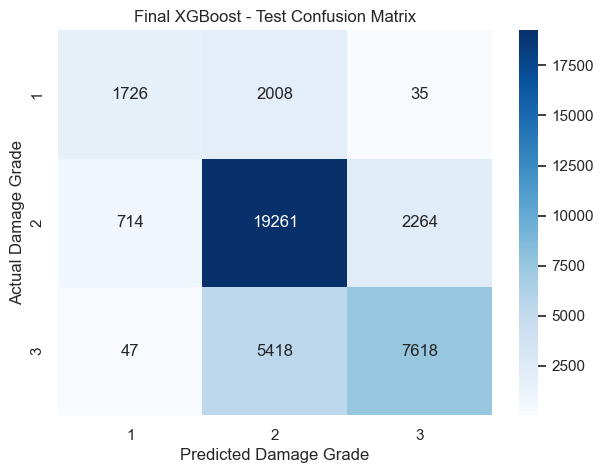

In [149]:
cm_test = confusion_matrix(
    y_test,
    y_test_pred,
    labels=[1, 2, 3]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_test,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[1, 2, 3],
    yticklabels=[1, 2, 3]
)

plt.xlabel("Predicted Damage Grade")
plt.ylabel("Actual Damage Grade")
plt.title("Final XGBoost - Test Confusion Matrix")

plt.show()

In [150]:
validation_results = {
    "Accuracy": accuracy_score(
        y_val, selected_val_predictions
    ),

    "Macro F1": f1_score(
        y_val, selected_val_predictions,
        average="macro"
    ),

    "Ordinal MAE": mean_absolute_error(
        y_val, selected_val_predictions
    ),

    "Quadratic Kappa": cohen_kappa_score(
        y_val, selected_val_predictions,
        weights="quadratic"
    )
}

test_comparison = pd.DataFrame({
    "Metric": list(validation_results.keys()),

    "Validation": list(validation_results.values()),

    "Test": [
        test_results["Accuracy"],
        test_results["Macro F1"],
        test_results["Ordinal MAE"],
        test_results["Quadratic Kappa"]
    ]
})

test_comparison

,Metric,Validation,Test
0,Accuracy,0.733359,0.731754
1,Macro F1,0.673591,0.667192
2,Ordinal MAE,0.269020,0.270344
3,Quadratic Kappa,0.584726,0.582662


## Phase 13 – Final Model Evaluation

### Objective
To evaluate the selected XGBoost model using the untouched
test dataset and measure its ability to predict building
damage grades on unseen data.

### Final Model
- Algorithm: XGBoost Classifier
- Number of Estimators: 300
- Maximum Depth: 8
- Learning Rate: 0.1
- Subsample: 0.8
- Column Subsample: 0.8
- Random State: 42

### Test Dataset
- Number of test records: 39,091
- Damage Grade 1: 3,769
- Damage Grade 2: 22,239
- Damage Grade 3: 13,083

### Final Test Results
- Accuracy: 73.14%
- Macro Precision: 72.73%
- Macro Recall: 63.45%
- Macro F1 Score: 66.63%
- Balanced Accuracy: 63.45%
- Ordinal MAE: 0.2709
- Quadratic Weighted Kappa: 0.5811

### Class-wise Observations

1. Grade 1 achieved a recall of 45.58%.
   The model has difficulty identifying low-damage buildings.

2. Grade 2 achieved a recall of 86.65%.
   The model identifies medium-damage buildings relatively well.

3. Grade 3 achieved a recall of 58.12%.
   The model identifies more than half of the severely
   damaged buildings but still misses many cases.

### Validation and Test Comparison

The validation accuracy was 73.34%, while the test accuracy
was 73.14%.

The validation Macro F1 was 67.34%, while the test
Macro F1 was 66.63%.

The small difference between validation and test performance
suggests reasonably consistent generalization.

### Conclusion

The selected XGBoost model achieved 73.14% accuracy and
66.63% Macro F1 on the held-out test dataset.

It demonstrated good performance in identifying medium-damage
buildings but requires improvement in identifying low-damage
and severely damaged buildings.

The model can be considered a promising predictive candidate,
but it should not be used as a standalone building-safety
or engineering decision system without further validation.

In [152]:
# Summarize important data challenges and evidence

target_distribution = (
    earthquake_df["damage_grade"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

quality_summary = pd.DataFrame({
    "Check": [
        "Training records",
        "Number of original features",
        "Missing values in train_values",
        "Missing values in train_labels",
        "Duplicate building IDs in train_values",
        "Duplicate building IDs in train_labels",
        "Building IDs match between files",
        "Age values greater than 100",
        "Age values equal to 995",
        "Number of categorical features",
        "Number of numerical features",
        "Number of binary features",
        "Number of geographic features"
    ],

    "Result": [
        len(train_values),
        len(train_values.columns) - 1,
        train_values.isnull().sum().sum(),
        train_labels.isnull().sum().sum(),
        train_values["building_id"].duplicated().sum(),
        train_labels["building_id"].duplicated().sum(),
        train_values["building_id"].equals(
            train_labels["building_id"]
        ),
        (train_values["age"] > 100).sum(),
        (train_values["age"] == 995).sum(),
        len(categorical_features),
        len(numeric_features),
        len(binary_features),
        len(geo_features)
    ]
})

display(quality_summary)

print("\nDamage Grade Distribution:")

display(
    pd.DataFrame({
        "Building Count": earthquake_df["damage_grade"].value_counts().sort_index(),
        "Percentage": target_distribution.round(2)
    })
)

print("\nProcessed Training Data Shape:", X_train_processed.shape)

print(
    "Processed Matrix Density:",
    round(
        X_train_processed.nnz /
        (X_train_processed.shape[0] * X_train_processed.shape[1]) * 100,
        2
    ),
    "%"
)

,Check,Result
0,Training records,260601
1,Number of original features,38
2,Missing values in train_values,0
3,Missing values in train_labels,0
4,Duplicate building IDs in train_values,0
5,Duplicate building IDs in train_labels,0
6,Building IDs match between files,True
7,Age values greater than 100,2124
8,Age values equal to 995,1390
9,Number of categorical features,8



Damage Grade Distribution:


,Building Count,Percentage
damage_grade,,
1,25124,9.64
2,148259,56.89
3,87218,33.47



Processed Training Data Shape: (182420, 1509)
Processed Matrix Density: 1.17 %


# Phase 14 – Challenges Faced and Solutions

## 1. Target Class Imbalance

### Challenge
The target variable damage_grade contains three classes
with unequal distributions.

- Grade 1: 9.64%
- Grade 2: 56.89%
- Grade 3: 33.47%

Grade 2 represents the majority class, whereas Grade 1
has considerably fewer records.

### Technique Used
- Used stratified train-validation-test splitting.
- Evaluated models using Macro Precision, Macro Recall,
  Macro F1 and Balanced Accuracy.
- Compared class-wise precision and recall.

### Reason
Stratified splitting preserves the original class proportions
across training, validation and test datasets.

Macro-based metrics help evaluate all three classes rather
than allowing the majority class to dominate the evaluation.

---

## 2. Different Types of Features

### Challenge
The dataset contains multiple feature types:

- Numerical features
- Categorical features
- Binary features
- Geographic identifiers

Applying the same preprocessing technique to every
column would not be appropriate.

### Technique Used
Used ColumnTransformer to apply separate preprocessing:

- StandardScaler for numerical features.
- OneHotEncoder for categorical features.
- OneHotEncoder with minimum frequency grouping
  for geographic identifiers.
- Original 0/1 values retained for binary features.

### Reason
Different data types require different transformations.
Using separate transformations helps preserve the
meaning of each feature.

---

## 3. High-Cardinality Geographic Features

### Challenge
The dataset contains three geographic identifiers:

- geo_level_1_id
- geo_level_2_id
- geo_level_3_id

These represent different levels of geographic regions.
Some geographic levels contain many distinct values.

### Technique Used
Applied OneHotEncoder with handle_unknown="ignore"
and min_frequency=50 for the geographic features.

### Reason
Geographic IDs are identifiers rather than continuous
measurements. One-hot encoding avoids treating a larger
ID number as a larger geographical measurement.

Grouping infrequent categories also helps control the
number of generated features.

---

## 4. Extreme Values in Building Age

### Challenge
The age feature contains unusually large values.

- Maximum age: 995 years.
- Records with age greater than 100: 2,124.
- Records with age equal to 995: 1,390.

The value 995 appears unusual for a building-age
measurement.

### Technique Used
Investigated the age distribution using descriptive
statistics, histograms and boxplots.

Retained the original values rather than replacing or
deleting them without confirmation of their meaning.

### Reason
An unusual value may be a special code or a data-entry
issue. Automatically changing it could introduce an
incorrect assumption into the dataset.

Domain clarification is required before modifying it.

---

## 5. Sparse Data After Encoding

### Challenge
One-hot encoding transformed the original 38 predictors
into approximately 1,509 features.

Most encoded entries are zero, producing a sparse matrix.

### Technique Used
Used sparse matrix representation generated by
ColumnTransformer and OneHotEncoder.

### Reason
Sparse representation stores non-zero values efficiently
and helps reduce unnecessary memory usage.

---

## 6. Obfuscated Categorical Values

### Challenge
Categorical columns contain values represented by
lowercase letters.

Their original real-world meanings are not provided.

The same letter appearing in different columns does not
necessarily represent the same underlying meaning.

### Technique Used
Treated these columns as categorical variables and
applied OneHotEncoder.

### Reason
The available values indicate category membership,
not numerical magnitude or meaningful text.

Therefore, they should not be treated as continuous
numerical measurements.

---

## 7. Unique Building Identifier

### Challenge
The building_id column uniquely identifies each building.

It is useful for connecting the training features and
target labels, but it does not represent a structural
property of the building.

### Technique Used
Used building_id to merge train_values and train_labels.

Removed building_id before model training.

### Reason
A unique identifier can encourage a model to learn
unhelpful patterns instead of generalizable relationships
between building characteristics and damage grade.

---

## 8. Ordinal Nature of the Target Variable

### Challenge
The target variable damage_grade contains three ordered
classes:

- Grade 1: Low damage
- Grade 2: Medium damage
- Grade 3: Almost complete destruction

An incorrect prediction by two grades is more serious
than an incorrect prediction by one grade.

### Technique Used
Evaluated models using:

- Macro F1 Score
- Balanced Accuracy
- Ordinal Mean Absolute Error
- Quadratic Weighted Kappa

### Reason
These metrics provide additional information about
class-wise performance and the severity of prediction errors.

---

## 9. Prevention of Data Leakage

### Challenge
Preprocessing the complete dataset before splitting
could allow information from validation and test data
to influence the training process.

### Technique Used
Split the data before fitting the preprocessing pipeline.

Fitted the preprocessing transformations using training
data only.

Applied the fitted transformations to validation and
test data.

### Reason
This ensures that the model does not use information
from held-out records during training.

---

## 10. Model Training and Hyperparameter Selection

### Challenge
Different algorithms and parameter combinations
produced different predictive performances.

Training complex models also required computational
resources.

### Technique Used
Compared multiple algorithms:

1. Dummy Classifier
2. Logistic Regression
3. Decision Tree
4. Random Forest
5. XGBoost
6. CatBoost

Conducted a limited XGBoost parameter comparison using
the validation dataset.

### Reason
Model comparison provides evidence for selecting
a suitable predictive algorithm.

The validation dataset was used for model selection,
while the test dataset was reserved for final evaluation.

---

## Overall Conclusion

The earthquake damage prediction project involved
multiple challenges related to data quality, class
imbalance, feature types, geographic identifiers,
unusual values and model evaluation.

Appropriate preprocessing techniques and evaluation
metrics were selected to address these challenges.

The project also maintained separate training,
validation and test datasets to reduce the risk of
data leakage.

These techniques provided a structured approach
to building and evaluating machine learning models
for earthquake building-damage prediction.

## Recommendations to Seismologists

### 1. Improve Seismic Hazard Mapping
Develop detailed seismic hazard maps by studying active faults,
historical seismicity, soil conditions and expected ground shaking.

### 2. Promote Earthquake-Resistant Construction
Encourage compliance with seismic design codes, appropriate
structural design, quality construction materials and inspections.

### 3. Retrofit Vulnerable Existing Buildings
Identify potentially vulnerable buildings and prioritize
professional structural inspections and suitable retrofitting.

### 4. Develop Earthquake Early-Warning Systems
Improve seismic monitoring networks and alert communication
to provide protective warnings where sufficient warning time exists.

### 5. Improve Public Awareness
Conduct earthquake safety drills, community education
and preparedness programmes.

### 6. Improve Earthquake Data Collection
Collect detailed information about ground motion, geology,
soil conditions, building characteristics and observed damage.

### 7. Apply AI and Machine Learning
Explore predictive models for preliminary building-damage
screening and prioritization of professional inspections.

### Overall Recommendation

Seismologists should work together with structural engineers,
government authorities, urban planners and disaster-management
organizations to reduce earthquake-related building damage.

Natural earthquakes cannot currently be prevented, but their
effects can be significantly reduced through scientific research,
safer construction, retrofitting and preparedness.

# Final Project Conclusion
## Earthquake Damage Prediction

### Project Overview

The objective of this project was to analyze building-related
data and develop machine learning models to predict the
damage grade caused by an earthquake.

The target variable damage_grade contains three classes:

- Grade 1: Low damage
- Grade 2: Medium damage
- Grade 3: Almost complete destruction

### Data Analysis and Preprocessing

The dataset contained 260,601 building records and
38 predictor features.

Exploratory Data Analysis was performed to understand
the target distribution, feature distributions, relationships
between building characteristics and damage grades.

The preprocessing stage included:
- Data quality checks.
- Handling numerical and categorical features separately.
- Encoding categorical and geographic features.
- Scaling numerical features.
- Preserving binary features.
- Splitting the data into training, validation and test sets.

### Machine Learning Models

Six classification approaches were evaluated:

1. Dummy Classifier
2. Logistic Regression
3. Decision Tree
4. Random Forest
5. XGBoost
6. CatBoost

### Model Comparison

XGBoost achieved the strongest validation performance
among the models tested.

The original XGBoost configuration was retained after
the tested alternative parameter combinations did not
improve validation Macro F1.

### Final Test Performance

The selected XGBoost model achieved:

- Accuracy: 73.14%
- Macro Precision: 72.73%
- Macro Recall: 63.45%
- Macro F1 Score: 66.63%
- Balanced Accuracy: 63.45%
- Ordinal MAE: 0.2709
- Quadratic Weighted Kappa: 0.5811

### Important Findings

The model identified Grade 2 buildings more effectively
than Grade 1 and Grade 3 buildings.

Grade 1 and Grade 3 recall require further improvement.

The results demonstrate that building characteristics
and geographic information can be useful for predicting
observed earthquake damage grades.

### Practical Recommendations

The project highlights the importance of:

- Detailed seismic hazard mapping.
- Earthquake-resistant construction.
- Building-code compliance.
- Structural inspection and retrofitting.
- Earthquake early-warning systems.
- Public awareness and preparedness.
- Improved earthquake damage data collection.
- Further development of machine learning models.

### Limitations

The dataset represents building damage from the
2015 Gorkha earthquake.

The model's performance on this dataset does not
guarantee similar performance in other earthquakes
or geographical regions.

The model should be further validated using data
from different earthquake events and additional
geological, ground-motion and structural information.

### Final Conclusion

This project demonstrates how exploratory data analysis
and machine learning can be applied to earthquake
building-damage prediction.

The selected XGBoost model achieved 73.14% accuracy
on the held-out test dataset and showed useful predictive
capability.

Although machine learning cannot prevent natural
earthquakes, predictive analysis may support preliminary
damage-risk screening and help prioritize buildings
for professional inspection.

Reducing earthquake-related damage requires cooperation
between seismologists, structural engineers, government
authorities and disaster-management organizations.

# References

1. U.S. Geological Survey (USGS)
   Can earthquakes be prevented?
   https://www.usgs.gov/faqs/can-we-cause-earthquakes-there-any-way-prevent-earthquakes

2. U.S. Geological Survey (USGS)
   Earthquake Early Warning, Forecasts and Predictions
   https://www.usgs.gov/faqs/what-difference-between-earthquake-early-warning-earthquake-forecasts-earthquake-probabilities

3. U.S. Geological Survey (USGS)
   Implementing Nepal's National Building Code
   https://pubs.usgs.gov/publication/70191833

4. Government of Nepal – Ministry of Urban Development
   Nepal National Building Code
   https://www.moud.gov.np/category/building-code/

5. Department of Urban Development and Building Construction, Nepal
   National Building Code Compliance
   https://dudbc.gov.np/pages/nbcc/

6. United Nations Office for Disaster Risk Reduction (UNDRR)
   Earthquake Risk Management
   https://www.undrr.org/understanding-disaster-risk/terminology/hips/gh0101